<a href="https://colab.research.google.com/github/jakob-steuer/chemoinformatics_course/blob/main/chemoinformatics_5_MD_simulation_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<a href="https://colab.research.google.com/github/jakob-steuer/chemoinformatics_2025/blob/main/chemoinformatics_5_MD_simulation_analysis_v2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Molecular Simulation Analysis

*Guanidine-II riboswitch + bivalent ligand — analysis of three MD trajectories.*

## Before you start

Run the next three cells (click the ▶ button on the left of each cell).
They download the simulation data (~55 MB), install the Python packages that Colab does not
ship by default, and import everything we need.

Together they take about 1–2 minutes.

> **If an import fails right after installing:** choose *Runtime → Restart session* in the menu
> and run the import cell again. This is a Colab quirk, not a mistake on your side.

In [1]:
# 1/3 — Download the simulation data from GitHub (structure + three trajectories)
import os

if os.path.isdir("FHNW-Summer-School-2025-MolSim-Analysis"):
    print("Simulation data is already here — nothing to download.")
else:
    !git clone --depth 1 https://github.com/jakob-steuer/FHNW-Summer-School-2025-MolSim-Analysis.git

Cloning into 'FHNW-Summer-School-2025-MolSim-Analysis'...
remote: Enumerating objects: 10, done.
remote: Counting objects: 100% (10/10), done.
remote: Compressing objects: 100% (10/10), done.
remote: Total 10 (delta 0), reused 6 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (10/10), 52.53 MiB | 14.48 MiB/s, done.
Updating files: 100% (7/7), done.


In [2]:
# 2/3 — Install the packages that are not pre-installed in Colab.
#
#   MDAnalysis  : reading and analysing MD trajectories
#   mdakit-sasa : solvent accessible surface area (SASA) for MDAnalysis
#   py3Dmol     : interactive 3D molecular viewer that works out of the box in Colab
#
# numpy, pandas, matplotlib, scikit-learn and tqdm are already available in Colab.
%pip install -q MDAnalysis mdakit-sasa py3Dmol

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 108.9/108.9 kB 2.3 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 270.1/270.1 kB 6.8 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.3/13.3 MB 38.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 51.8/51.8 kB 3.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.6/5.6 MB 57.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 45.0/45.0 kB 1.2 MB/s eta 0:00:00


In [3]:
# 3/3 — Imports and plot defaults
import io
import warnings
import contextlib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

import MDAnalysis as mda
from MDAnalysis.analysis import align, rms
from MDAnalysis.analysis import distances as mdadist
from MDAnalysis.analysis.hydrogenbonds.hbond_analysis import HydrogenBondAnalysis

import py3Dmol

from sklearn.decomposition import PCA
from sklearn.cluster import HDBSCAN
from sklearn.metrics.pairwise import euclidean_distances

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.figsize": (10, 5), "axes.grid": True, "grid.alpha": 0.3,
                     "font.size": 11, "figure.dpi": 110})

print("MDAnalysis", mda.__version__)
print("Everything imported — you are ready to go.")

MDAnalysis 2.10.0
Everything imported — you are ready to go.


# Introduction to Molecular Simulation of RNA for Drug Discovery

In this tutorial we will go through some basic steps toward the **analysis** of **molecular dynamics (MD)simulations** of an **RNA riboswitch**.
In this exercise, you will have the opportunity to apply your knowledge of computational chemistry and bioinformatics to an interesting research problem in **drug discovery**.

<img src="https://www.mdpi.com/molecules/molecules-26-03384/article_deploy/html/images/molecules-26-03384-g002.png" width="80%">

From: Berdnikova, D. V., Carloni, P., Krauß, S., & Rossetti, G. (2021). Role and Perspective of Molecular Simulation-Based Investigation of RNA–Ligand Interaction: From Small Molecules and Peptides to Photoswitchable RNA Binding. Molecules, 26(11), 3384. https://doi.org/10.3390/molecules26113384




## Molecular Simulation in Drug Discovery

**Molecular simulation** has become an indispensable tool in modern **drug discovery**.
By computationally modeling the behavior of biological macromolecules and their interactions with potential drug molecules, we can gain insights into the **molecular basis of disease** and **design novel therapeutics**.

Techniques such as molecular dynamics allow us to simulate the time-evolution of a system at the atomic level providing a **"computational microscope"** to observe processes that are often difficult to study experimentally.
These simulations can be used to predict **binding affinities**, understand **mechanisms of action**, and identify new **binding sites**, thereby accelerating the drug development pipeline.

## The Challenge and Promise of RNA Simulations

While much of the focus in computational drug discovery has been on protein targets, **RNA** is emerging as a new frontier.

RNA molecules play a wide range of crucial roles in the cell, from **carrying genetic information** to **catalyzing biochemical reactions**.
However, simulating RNA presents unique challenges compared to proteins. The high charge density of the phosphate backbone, the flexibility of the sugar-phosphate backbone, and the complex, often non-canonical, tertiary structures of RNA make accurate and efficient simulation a difficult task.

Despite these challenges, the increasing number of identified RNA drug targets makes the development of robust simulation protocols a **key area of research in medicinal chemistry**.

Accurate simulation models for RNA require a delicate balancing of underlying driving forces.

<img src="https://wires.onlinelibrary.wiley.com/cms/asset/14c103e4-3020-4149-9872-086169b39849/wrna1396-toc-0001-m.jpg" width="40%">

From: Vangaveti, S., Ranganathan, S. V., & Chen, A. A. (2016). Advances in RNA molecular dynamics: a simulator’s guide to RNA force fields. WIREs RNA, 8(2). https://doi.org/10.1002/wrna.1396

## Riboswitches: RNA's Molecular Switches

A fascinating class of RNA drug targets are **riboswitches**.
These are regulatory regions found in messenger RNA (mRNA) that can directly bind to small molecules, or ligands, and in response, alter their three-dimensional structure.
This conformational change, in turn, regulates the expression of the gene encoded by the mRNA.
Because they are involved in the regulation of essential metabolic pathways in bacteria, riboswitches are attractive targets for the development of new antibiotics.

In this exercise, we will focus on the **guanidine-II riboswitch**.
This riboswitch, found in various bacteria, controls the expression of genes involved in guanidine detoxification.

It functions as a dimer, with each monomeric aptamer domain capable of binding a single guanidine molecule.
The binding of the ligand stabilizes a conformation that promotes gene expression.

## The Exercise: Analyzing Ligand Binding Events

You will be working with MD trajectories of the dimerized aptamer domains of the guanidine-II riboswitch in complex with a specially designed, **divalent guanidine ligand**.

This ligand, with two guanidinium groups connected by a linker, was designed to bridge the two binding sites of the riboswitch dimer.

The simulation data you will be analyzing is from the following publication:

Steuer, J., Sinn, M., Eble, F., Rütschlin, S., Böttcher, T., Hartig, J. S., & Peter, C. (2024). Cooperative binding of bivalent ligands yields new insights into the guanidine-II riboswitch. NAR Genomics and Bioinformatics, 6(3). https://doi.org/10.1093/nargab/lqae132

<img src="https://oup.silverchair-cdn.com/oup/backfile/Content_public/Journal/nargab/6/3/10.1093_nargab_lqae132/2/m_lqae132fig1.jpeg?Expires=1759496277&Signature=ENjfYKAkjNXeNVBsObC~8xpV7FdJ3hvNzxAX~Mu~yaq33ctRhCFidpSm5hND7RWSlST4ejOaBz72RZRB6-otiYVtc58rWc1MPI0Pyj90vSDULilWCOs00-unSFZOXkBoQTDV3fSeYfrUaA~yVeiFgHLXM646d6TLU5crFdc8xX28mfbGaFoEGV2fwHq0xdDp4fI3yGNlZ3cOId2KZYGVlwRCNsuOEUiUJrYTxyim-5fJZQB~yw8xwVoGL55cwL9eCKdOSlT4soAZ960nsFJ0i7VwzCxIXAg4Wk47g3YpsmjYK9KAw2JeEmMKDAFPAVsIhJS5vKDSg3BZl0~uibYVSA__&Key-Pair-Id=APKAIE5G5CRDK6RD3PGA" width="80%">

Your task will be to analyze these trajectories to observe and characterize the ligand binding events.

One of the key findings in the paper was the spontaneous binding of the divalent ligand to the second binding site, a rare event to capture in simulations.

By analyzing these trajectories, you will gain hands-on experience in the analysis of MD simulations and contribute to our understanding of the molecular mechanism of this promising RNA drug target.

# Part 1 — Getting to know the system

We will start with the first trajectory, in which **no ligand binding** occurs, and then bring in
the two trajectories that **do** show a binding event.

## Open the simulation data in the notebook

For this course the published simulation data has already been processed to reduce the length and
the size of the trajectories: all solvent molecules were removed and only the parts of the
trajectories around the binding events were kept.

MDAnalysis stores a simulation in a **Universe**: a *topology* (which atoms exist, how they are
named, which residue and chain they belong to — here a PDB file) plus a *trajectory*
(where the atoms are at every point in time — here an XTC file).

Each of the three trajectories is 4 µs long with one frame every nanosecond. We count time from
the beginning of each trajectory, so all three start at 0 µs.

In [4]:
PDB_FILE = "FHNW-Summer-School-2025-MolSim-Analysis/data/structure.pdb"       # topology
XTC_FILES = [
    "FHNW-Summer-School-2025-MolSim-Analysis/data/traj.simulation_1.0mus-4mus.dt1ns.xtc",
    "FHNW-Summer-School-2025-MolSim-Analysis/data/traj.simulation_4.6mus-10mus.dt1ns.xtc",
    "FHNW-Summer-School-2025-MolSim-Analysis/data/traj.simulation_7.3mus-7mus.dt1ns.xtc",
]
SIM_NAMES = ["Simulation 1", "Simulation 4", "Simulation 7"]
SIM_COLORS = ["#4477aa", "#ee7733", "#228833"]

print("Loading trajectories ...")
universes = [mda.Universe(PDB_FILE, xtc) for xtc in XTC_FILES]
u1, u4, u7 = universes

for u, name in zip(universes, SIM_NAMES):
    length_us = u.trajectory.n_frames * u.trajectory.dt / 1e6   # MDAnalysis stores time in ps
    print(f"{name}: {u.atoms.n_atoms:5d} atoms | {u.trajectory.n_frames:5d} frames | "
          f"length {length_us:.1f} µs | 1 frame = {u.trajectory.dt/1000:.0f} ns")


def time_axis(universe):
    """Simulation time of every frame in µs, counted from the start of the trajectory."""
    return np.arange(universe.trajectory.n_frames) * universe.trajectory.dt / 1e6

Loading trajectories ...
Simulation 1:  1196 atoms |  4001 frames | length 4.0 µs | 1 frame = 1 ns
Simulation 4:  1196 atoms |  4001 frames | length 4.0 µs | 1 frame = 1 ns
Simulation 7:  1196 atoms |  4001 frames | length 4.0 µs | 1 frame = 1 ns


### What is in the box?

Before analysing anything, always look at what the system actually contains — the atom names and
residue names decide every selection you will write later.

In [5]:
print("Segments (chains):")
for seg in universes[0].segments:
    print(f"  segid {seg.segid}: {len(seg.residues):2d} residues "
          f"({''.join(r.resname for r in seg.residues)})")

ligand = universes[0].select_atoms("resname BGD")
print(f"\nLigand BGD: {ligand.n_atoms} atoms")
print("  atom names:", " ".join(ligand.names))

Segments (chains):
  segid A: 18 residues (GGUGGGGACGACCCCACC)
  segid B: 18 residues (GGUGGGGACGACCCCACC)
  segid C:  1 residues (BGD)

Ligand BGD: 30 atoms
  atom names: C1 N1 N2 C2 C3 C4 C5 N3 C6 N4 N5 H1 H2 H3 H4 H5 H6 H7 H8 H9 H10 H11 H12 H13 H14 N6 H15 H16 H17 H18


### The selections we will use throughout

MDAnalysis uses a selection language similar to VMD. Defining the important groups **once**, with
a readable name, keeps the rest of the notebook short and prevents copy-paste mistakes.

The ligand consists of two guanidinium groups connected by a short alkyl linker:

* **C6–N3/N4/N5** — the head that is **already bound** in chain B at the start of every simulation
* **C1–N1/N2/N6** — the **free** head, which may bind into the empty pocket of chain A

The binding pocket is formed by residues **7–10** of each chain.

In [6]:
RNA         = "nucleic"
RNA_HEAVY   = "nucleic and not name H*"          # heavy atoms only: less noise, faster
LIGAND      = "resname BGD"

FREE_HEAD   = "resname BGD and name C1 N1 N2 N6"            # guanidinium that is still free
FREE_HEAD_H = "resname BGD and name H1 H15 H16 H17 H18"     # its hydrogens (H-bond donors)
BOUND_HEAD  = "resname BGD and name C6 N3 N4 N5"            # guanidinium bound from the start

POCKET_A    = "segid A and resid 7 8 9 10"       # the empty ("second") binding site
POCKET_B    = "segid B and resid 7 8 9 10"       # the site that is occupied from the start

for label, sel in [("RNA heavy atoms", RNA_HEAVY), ("free guanidinium", FREE_HEAD),
                   ("bound guanidinium", BOUND_HEAD), ("pocket A", POCKET_A)]:
    print(f"{label:20s} -> {universes[0].select_atoms(sel).n_atoms:4d} atoms")

RNA heavy atoms      ->  768 atoms
free guanidinium     ->    4 atoms
bound guanidinium    ->    4 atoms
pocket A             ->  132 atoms


## A 3D viewer for the notebook

We use **py3Dmol** (the Python interface to [3Dmol.js](https://3dmol.csb.pitt.edu/)). It writes
plain HTML and JavaScript into the cell output, which is why it works in Google Colab without any
further configuration.

The next cell defines three small helpers that we will reuse for every 3D picture:

| helper | purpose |
|---|---|
| `to_pdb(atoms)` | turn the current frame of an MDAnalysis selection into a PDB string |
| `to_pdb_frames(atoms, ...)` | turn *several* frames into one multi-model PDB string (for animations) |
| `show(...)` | display a structure, optionally coloured by B-factor or animated |

One detail worth knowing: 3Dmol **discards hydrogens** when it reads a PDB file unless you ask it
not to (`keepH`). For this system the hydrogens matter — the ligand binds through the N–H groups
of its guanidinium head — so `show()` keeps them and, by default, draws them on the **ligand**
while hiding them on the RNA, which would otherwise be a thicket of white sticks. Use
`hydrogens="all"` or `hydrogens="none"` to change that.

For a close-up of a binding site, pass `style="sticks"`: the cartoon ribbon is dropped and
everything is drawn as sticks, which is how you would normally look at a few residues and a
ligand together.

> For publication-quality pictures you would still use a dedicated viewer such as ChimeraX, VMD,
> PyMOL or SAMSON. (If you would rather use `nglview`, see the appendix at the end of this
> notebook.)

In [7]:
LIGAND_RESNAME = "BGD"
HEAVY_ELEMENTS = ["C", "N", "O", "P"]


def to_pdb(atoms):
    """Return the current frame of an MDAnalysis AtomGroup as a PDB-formatted string."""
    stream = io.StringIO()
    with mda.lib.util.NamedStream(stream, "frame.pdb") as handle:
        with mda.Writer(handle, n_atoms=atoms.n_atoms) as writer:
            writer.write(atoms)
    return stream.getvalue()


def to_pdb_frames(atoms, start=0, stop=None, step=1):
    """Return several trajectory frames as one multi-model PDB string (used for animations)."""
    stream = io.StringIO()
    with mda.lib.util.NamedStream(stream, "traj.pdb") as handle:
        with mda.Writer(handle, n_atoms=atoms.n_atoms, multiframe=True) as writer:
            for _ in atoms.universe.trajectory[start:stop:step]:
                writer.write(atoms)
    return stream.getvalue()


def show(structure, style="cartoon", color_by=None, vmin=None, vmax=None, highlight=None,
         zoom_on=None, hydrogens="ligand", animate=False, spin=False, width=800, height=520):
    """Show a structure in 3D.

    structure : an MDAnalysis AtomGroup, or a PDB string (e.g. from `to_pdb_frames`)
    style     : "cartoon" (default) for whole molecules,
                "sticks" for a close-up of a few residues
    color_by  : None -> chain A blue, chain B orange, ligand magenta
                "bfactor" -> colour by the B-factor column (blue = low, red = high)
    vmin/vmax : colour range for color_by="bfactor"
    highlight : 3Dmol selection drawn as thick green sticks, e.g. {"chain": "A", "resi": [7, 8]}
    zoom_on   : 3Dmol selection to zoom in on, e.g. {"resn": "BGD"}
    hydrogens : "ligand" (default) -> hydrogens on the ligand only
                "all" -> also on the RNA; "none" -> no hydrogens at all
    animate   : True if `structure` is a multi-model PDB string
    """
    pdb = structure if isinstance(structure, str) else to_pdb(structure)
    # 3Dmol throws hydrogens away while parsing a PDB file unless we ask it to keep them.
    options = {"keepH": True}

    view = py3Dmol.view(width=width, height=height)
    if animate:
        view.addModelsAsFrames(pdb, "pdb", options)
    else:
        view.addModel(pdb, "pdb", options)

    ligand_style = {"stick": {"radius": 0.20, "colorscheme": "magentaCarbon"},
                    "sphere": {"scale": 0.22, "colorscheme": "magentaCarbon"}}

    if color_by == "bfactor":
        # 3Dmol's "roygb" gradient runs red -> blue. Passing min/max the other way round
        # flips it, so that low values are blue (rigid) and high values red (flexible).
        scheme = {"prop": "b", "gradient": "roygb", "min": float(vmax), "max": float(vmin)}
        view.setStyle({}, {"stick": {"radius": 0.16, "colorscheme": scheme},
                           "sphere": {"scale": 0.20, "colorscheme": scheme}})
    else:
        if style == "sticks":                 # close-up: no cartoon, everything as sticks
            view.setStyle({}, {"stick": {"radius": 0.14, "colorscheme": "lightgreyCarbon"},
                               "sphere": {"scale": 0.16, "colorscheme": "lightgreyCarbon"}})
        else:
            view.setStyle({"chain": "A"},
                          {"cartoon": {"color": "#6699dd", "opacity": 0.85},
                           "stick": {"radius": 0.08, "colorscheme": "lightblueCarbon"}})
            view.setStyle({"chain": "B"},
                          {"cartoon": {"color": "#eeaa55", "opacity": 0.85},
                           "stick": {"radius": 0.08, "colorscheme": "yellowCarbon"}})
        if hydrogens != "all":
            view.setStyle({"elem": "H"}, {})          # hide every hydrogen ...
        if hydrogens == "none":
            view.setStyle({"resn": LIGAND_RESNAME, "elem": HEAVY_ELEMENTS}, ligand_style)
        else:
            view.setStyle({"resn": LIGAND_RESNAME}, ligand_style)   # ... bring the ligand back

    if highlight is not None:
        selection = dict(highlight) if hydrogens == "all" else dict(highlight, elem=HEAVY_ELEMENTS)
        view.addStyle(selection, {"stick": {"radius": 0.25, "colorscheme": "greenCarbon"}})

    view.setBackgroundColor("white")
    view.zoomTo(zoom_on) if zoom_on else view.zoomTo()
    if animate:
        view.animate({"loop": "forward", "interval": 120})
    if spin:
        view.spin(True)
    return view


print("Viewer helpers ready.")

Viewer helpers ready.


## Look at the RNA structure

Drag with the mouse to rotate, scroll to zoom, right-drag (or two-finger drag) to translate.

* **blue** — RNA chain A, with its (still empty) binding pocket in **green**
* **orange** — RNA chain B
* **magenta** — the bivalent ligand; one of its two guanidinium heads already sits in chain B

In [8]:
u1.trajectory[0]      # make sure we look at the first frame

show(u1.atoms, highlight={"chain": "A", "resi": [7, 8, 9, 10]})

3Dmol.js failed to load for some reason. Please check your browser console for error messages.

Zooming in on the empty pocket of chain A shows what the free guanidinium head has to find:

In [9]:
show(u1.atoms,
     highlight={"chain": "A", "resi": [7, 8, 9, 10]},
     zoom_on={"chain": "A", "resi": [7, 8, 9, 10, 11, 12]})

3Dmol.js failed to load for some reason. Please check your browser console for error messages.

## Root Mean Square Deviation (RMSD)

The **RMSD** measures the average distance between the atoms of a structure at a given timepoint and a reference structure.
It's the go-to metric for assessing the structural stability of a simulation.

- A low and stable RMSD (i.e., it plateaus) suggests the molecule has reached equilibrium and is not undergoing major conformational changes.

- A continuously increasing or wildly fluctuating RMSD indicates significant structural changes, instability, or that the system has not yet equilibrated.

Two practical points:

* **RMSD always needs a reference.** We use the experimental starting structure
  (`structure.pdb`) for all three simulations, so the curves can be compared with each other.
* `rms.RMSD` **superimposes** every frame onto the reference before measuring the distances, so we
  do *not* have to align the trajectory beforehand. (For the RMSF in the next section we *do*.)
* MDAnalysis works in **ångström (Å)**, not nanometres.

In [10]:
reference = mda.Universe(PDB_FILE)          # the experimental structure, used as reference

print("Calculating RMSD ...")
rmsd_analysis = rms.RMSD(u1, reference, select=RNA_HEAVY).run(verbose=True)

# column 0 = frame, column 1 = time, column 2 = RMSD (Å)
rmsd_1 = rmsd_analysis.results.rmsd[:, 2]
time_us_1 = time_axis(u1)

print(f"RMSD: mean {rmsd_1.mean():.2f} Å, min {rmsd_1.min():.2f} Å, max {rmsd_1.max():.2f} Å")

Calculating RMSD ...


  0%|          | 0/4001 [00:00<?, ?it/s]

RMSD: mean 1.80 Å, min 0.82 Å, max 3.87 Å


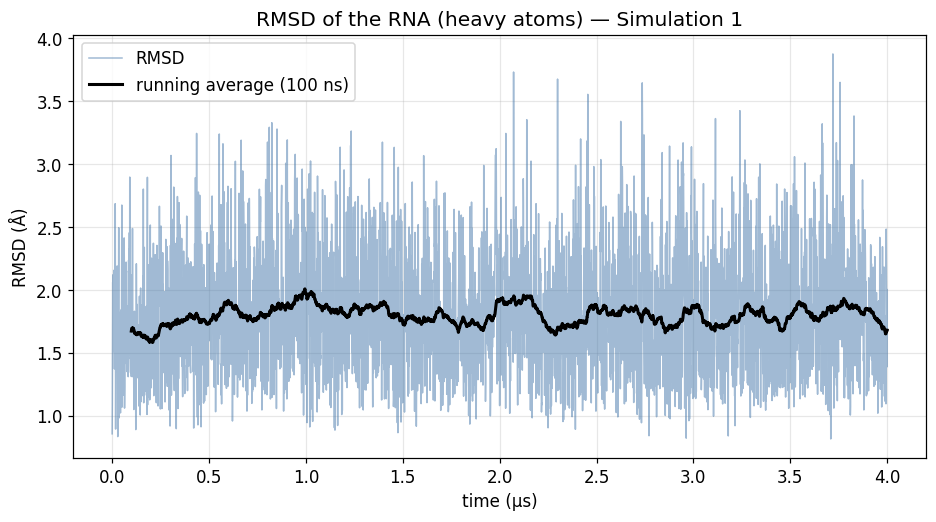

In [11]:
def running_average(values, window=100):
    return np.convolve(values, np.ones(window) / window, mode="valid")


plt.figure()
plt.plot(time_us_1, rmsd_1, lw=1, alpha=0.5, color=SIM_COLORS[0], label="RMSD")
plt.plot(time_us_1[99:], running_average(rmsd_1), lw=2, color="black",
         label="running average (100 ns)")
plt.title("RMSD of the RNA (heavy atoms) — Simulation 1")
plt.xlabel("time (µs)")
plt.ylabel("RMSD (Å)")
plt.legend()
plt.show()

### Exercise 1 — RMSD of the other two trajectories

Calculate and plot the RMSD for **Simulation 4** and **Simulation 7** as well, and draw all three
curves in a single figure. Do all three simulations look equally stable?

<details>
<summary>🔍 Click here for the solution (try it yourself first!)</summary>

```python
plt.figure()

for u, name, color in zip(universes, SIM_NAMES, SIM_COLORS):
    result = rms.RMSD(u, reference, select=RNA_HEAVY).run()
    rmsd = result.results.rmsd[:, 2]
    time_us = time_axis(u)
    plt.plot(time_us, rmsd, lw=0.8, alpha=0.35, color=color)
    plt.plot(time_us[99:], running_average(rmsd), lw=2, color=color, label=name)

plt.title("RMSD of the RNA (heavy atoms), all three simulations")
plt.xlabel("time (µs)")
plt.ylabel("RMSD (Å)")
plt.legend()
plt.show()
```

**What you should see:** all three curves fluctuate around 2–4 Å without drifting upwards — the
RNA dimer is stable in all three simulations. And none of them shows anything you could point at
and call "the binding event": a global quantity such as the RMSD of the whole dimer is almost
blind to it, because it involves only a single, small ligand head.

</details>

## Root Mean Square Fluctuation (RMSF)

The **RMSF** measures the fluctuation of each individual residue over the course of the simulation. Instead of showing how the whole structure changes over time (like RMSD), RMSF shows which parts of the structure are the most mobile.

- High RMSF values indicate regions of high flexibility, such as loops or the N/C-termini of proteins.

- Low RMSF values indicate stable regions, like the core of a protein or residues constrained by ligand binding or base-pairing in RNA.

Unlike the RMSD, the RMSF is **not** invariant under rotation: before measuring how much an atom
moves, we have to remove the overall tumbling of the molecule. The usual recipe is

1. compute the **average structure** of the trajectory,
2. **align** every frame onto that average structure,
3. then compute the fluctuation of each atom around its average position.

In [12]:
# Work on a separate copy of the trajectory, so that the alignment does not change `u1`.
u1_aligned = mda.Universe(PDB_FILE, XTC_FILES[0], in_memory=True)

print("Computing the average structure ...")
average = align.AverageStructure(u1_aligned, reference, select=RNA_HEAVY).run(verbose=True)

print("Aligning every frame onto the average structure ...")
align.AlignTraj(u1_aligned, average.results.universe, select=RNA_HEAVY, in_memory=True).run(verbose=True)

print("Calculating RMSF ...")
rna_heavy = u1_aligned.select_atoms(RNA_HEAVY)
rmsf_per_atom = rms.RMSF(rna_heavy).run(verbose=True).results.rmsf

print(f"RMSF: {rmsf_per_atom.min():.2f} – {rmsf_per_atom.max():.2f} Å "
      f"over {rna_heavy.n_atoms} heavy atoms")

Computing the average structure ...


  0%|          | 0/4001 [00:00<?, ?it/s]

Aligning every frame onto the average structure ...


  0%|          | 0/4001 [00:00<?, ?it/s]

Calculating RMSF ...


  0%|          | 0/4001 [00:00<?, ?it/s]

RMSF: 0.65 – 2.94 Å over 768 heavy atoms


A per-atom plot is noisy. Averaging the atoms of each nucleotide gives a much more readable
picture of **which residues** are mobile — and it lets us compare the two chains directly.

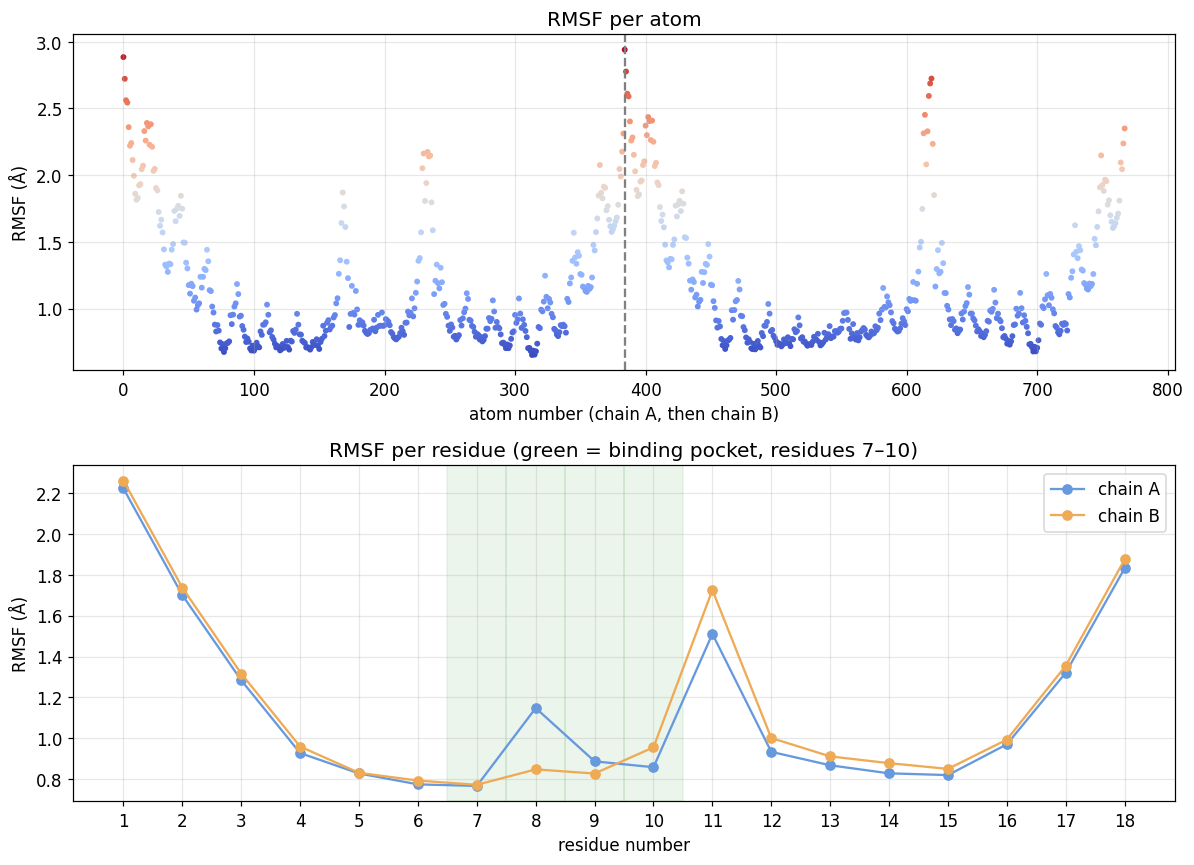

In [13]:
rmsf_table = pd.DataFrame({"segid": rna_heavy.segids, "resid": rna_heavy.resids,
                           "resname": rna_heavy.resnames, "rmsf": rmsf_per_atom})
per_residue = rmsf_table.groupby(["segid", "resid"], as_index=False).agg(
    rmsf=("rmsf", "mean"), resname=("resname", "first"))

fig, axes = plt.subplots(2, 1, figsize=(11, 8))

axes[0].scatter(np.arange(len(rmsf_per_atom)), rmsf_per_atom, c=rmsf_per_atom,
                cmap="coolwarm", s=8)
axes[0].set_title("RMSF per atom")
axes[0].set_xlabel("atom number (chain A, then chain B)")
axes[0].set_ylabel("RMSF (Å)")
axes[0].axvline(len(rmsf_per_atom) / 2, ls="--", color="grey")

for (segid, group), color in zip(per_residue.groupby("segid"), ["#6699dd", "#eeaa55"]):
    axes[1].plot(group["resid"], group["rmsf"], "o-", color=color, label=f"chain {segid}")
for resid in (7, 8, 9, 10):
    axes[1].axvspan(resid - 0.5, resid + 0.5, color="green", alpha=0.08)
axes[1].set_title("RMSF per residue (green = binding pocket, residues 7–10)")
axes[1].set_xlabel("residue number")
axes[1].set_ylabel("RMSF (Å)")
axes[1].set_xticks(per_residue["resid"].unique())
axes[1].legend()

plt.tight_layout()
plt.show()

### The RMSF on the structure itself

A standard trick: write the RMSF values into the **B-factor column** of the structure and colour
the 3D model by it. Blue = rigid, red = flexible.

(We clip the colour scale at the 2nd and 90th percentile, otherwise a single very mobile terminal
atom would use up the whole colour range.)

In [14]:
rna_heavy.tempfactors = rmsf_per_atom          # store RMSF in the B-factor column

low, high = np.percentile(rmsf_per_atom, [2, 90])
print(f"colour scale: {low:.2f} Å (blue, rigid) → {high:.2f} Å (red, flexible)")

show(rna_heavy, color_by="bfactor", vmin=low, vmax=high)

colour scale: 0.70 Å (blue, rigid) → 1.89 Å (red, flexible)


3Dmol.js failed to load for some reason. Please check your browser console for error messages.

### Exercise 2 — Where is the RNA rigid, and where does it move?

Using the per-residue plot and the 3D picture, answer:

1. Which parts of the aptamer are the most flexible?
2. Are the two chains equally flexible — and if not, can you think of a reason?
3. How do the pocket residues 7–10 compare to the rest of the molecule?

<details>
<summary>🔍 Click here for a discussion of the answer</summary>

1. The **5′ and 3′ ends** (residues 1–2 and 18, ≈ 1.8–2.3 Å) and the **loop around residue 11**
   (≈ 1.5–1.7 Å) fluctuate most, while the base-paired stem stays near 0.8 Å. This is the generic
   picture for a nucleic acid: stacking and Watson–Crick pairing stiffen the helix, free ends have
   nothing holding them.
2. The two chains are **not** exactly equivalent even though their sequence is identical. The
   clearest difference is at residue **A8**, part of the binding pocket: ≈ 1.15 Å in chain A
   against ≈ 0.85 Å in chain B. Chain B holds a guanidinium head from the first frame on, and a
   bound ligand rigidifies the residues that coordinate it — the same A8 phosphate oxygens that
   show up in the hydrogen bond analysis later on. The empty pocket of chain A can breathe.
3. Apart from A8, the pocket residues are among the **more rigid** parts of the molecule: the
   binding site is largely pre-organised, which is exactly what makes the riboswitch a plausible
   drug target.

A useful follow-up: re-run this analysis for `u7` (which spends most of its time with *both*
pockets occupied) and check whether the difference at A8 disappears.

</details>

## Solvent Accessible Surface Area (SASA)

The **SASA** is the surface area of the molecule that is accessible to the solvent.
It's a great way to measure changes in the molecule's overall shape and compactness.

- A decreasing SASA can indicate that the molecule is folding or becoming more compact.

- An increasing SASA can suggest unfolding or a conformational change that exposes more of the molecule to the solvent.

It's particularly useful for observing how a binding event might bury a previously exposed surface.

Two kinds of harmless noise come out of this calculation, and both would otherwise bury the
result in thousands of lines:

* `freesasa` warns about every atom name it does not recognise (it expects proteins), and then
  falls back to the element — which is what we want anyway;
* `mdakit-sasa` logs `Residude count do not match the expectation ... 37 != 36` once per frame. It
  compares the number of residues in the *whole* Universe (36 nucleotides + 1 ligand) with the
  number in the *selection* we passed. Only the per-residue bookkeeping is affected; the total
  area we use is correct.

The next cell silences both.

In [15]:
import logging

import freesasa
from mdakit_sasa.analysis.sasaanalysis import SASAAnalysis

freesasa.setVerbosity(freesasa.silent)                      # atom-name warnings
logging.getLogger("mdakit_sasa").setLevel(logging.CRITICAL)  # per-frame residue-count messages


@contextlib.contextmanager
def quiet():
    """Suppress anything the SASA machinery still prints."""
    with contextlib.redirect_stdout(io.StringIO()), contextlib.redirect_stderr(io.StringIO()):
        yield


STEP = 10          # SASA is expensive — analyse every 10th frame (= every 10 ns)

print("Calculating SASA ...")
with quiet():
    sasa = SASAAnalysis(u1.select_atoms(RNA)).run(step=STEP)

sasa_total = np.asarray(sasa.results.total_area)        # Å² per frame
sasa_time_us = time_axis(u1)[::STEP]
print(f"SASA: mean {sasa_total.mean():.0f} Å², range {sasa_total.min():.0f}–{sasa_total.max():.0f} Å²")

Calculating SASA ...
SASA: mean 6634 Å², range 6441–6808 Å²


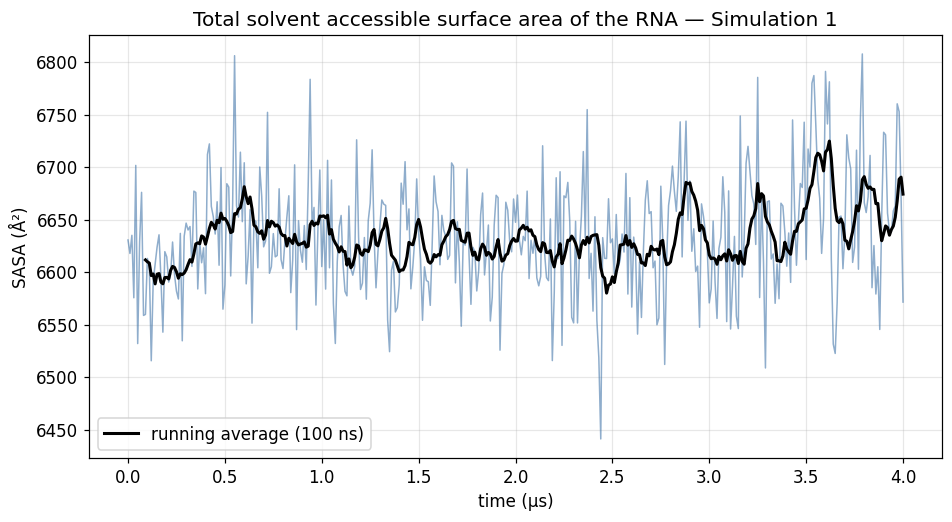

In [16]:
plt.figure()
plt.plot(sasa_time_us, sasa_total, lw=1, alpha=0.6, color=SIM_COLORS[0])
plt.plot(sasa_time_us[9:], running_average(sasa_total, 10), lw=2, color="black",
         label="running average (100 ns)")
plt.title("Total solvent accessible surface area of the RNA — Simulation 1")
plt.xlabel("time (µs)")
plt.ylabel("SASA (Å²)")
plt.legend()
plt.show()

## Radius of Gyration (Rg)

The **Radius of Gyration (Rg)** is a measure of a molecule's overall compactness.
It's calculated as the root mean square distance of the atoms from their common center of mass.
Think of it as describing the effective "size" of the molecule in each frame.
It's complementary to SASA but focuses on the mass distribution rather than surface exposure.

- A stable Rg value indicates the molecule maintains a consistent size and shape.

- A decreasing Rg suggests the molecule is becoming more compact (folding).

- An increasing Rg suggests it's expanding or unfolding.

Calculating the radius of gyration ...


Simulation 1:   0%|          | 0/4001 [00:00<?, ?it/s]

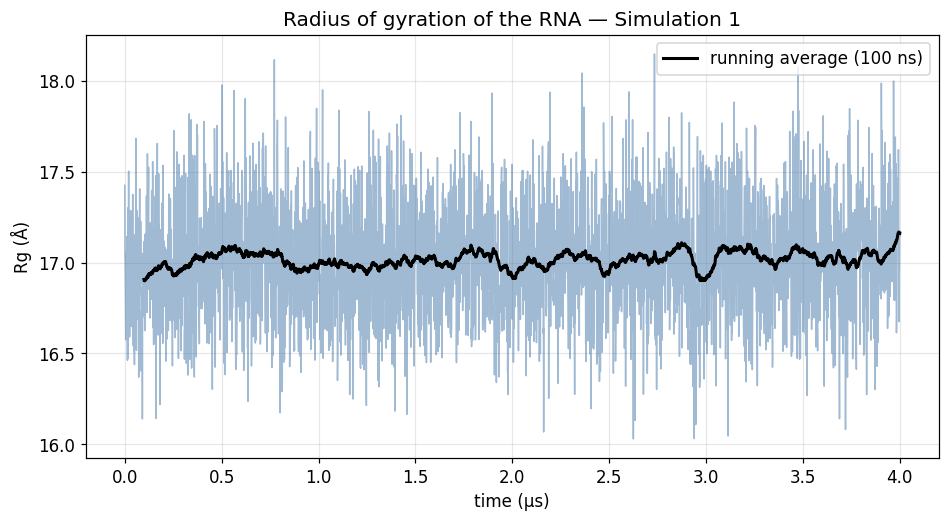

In [17]:
print("Calculating the radius of gyration ...")
rg_values = np.array([u1.select_atoms(RNA).radius_of_gyration()
                      for _ in tqdm(u1.trajectory, desc="Simulation 1")])
rg_time_us = time_axis(u1)

plt.figure()
plt.plot(rg_time_us, rg_values, lw=1, alpha=0.5, color=SIM_COLORS[0])
plt.plot(rg_time_us[99:], running_average(rg_values), lw=2, color="black",
         label="running average (100 ns)")
plt.title("Radius of gyration of the RNA — Simulation 1")
plt.xlabel("time (µs)")
plt.ylabel("Rg (Å)")
plt.legend()
plt.show()

### Question 1 — What do RMSD, RMSF, SASA and Rg tell you so far?

All four quantities are *global* descriptors of the RNA. Looking at the four plots: would you be
able to tell from them whether a ligand binding event happened in this simulation? What does that
imply for the analysis of a rare event such as ligand binding?

<details>
<summary>🔍 Click here for a discussion of the answer</summary>

No — and that is the point. RMSD, Rg and total SASA are dominated by the ~1200 atoms of the RNA
dimer; a single guanidinium group moving by a few ångström changes them by less than the thermal
noise. Global descriptors are good for **quality control** (is the simulation stable? did the
structure fall apart?), but to see a rare, local event you need descriptors that are **specific to
the event**: distances to the binding site, hydrogen bonds with the pocket, the buried surface
area of the ligand. That is exactly what we build in Part 2.

</details>

# Part 2 — Finding the binding event

From here on we analyse all three simulations together. Every quantity we compute is stored as one
column of a single table (`frames`), with **one row per simulation frame**. Keeping everything in
one `DataFrame` means the rows always stay in the same order, so later we can colour any plot by
any descriptor without worrying about matching up indices.

In [18]:
rows = []
for u, name in zip(universes, SIM_NAMES):
    for frame, time_us in enumerate(time_axis(u)):
        rows.append({"simulation": name, "frame": frame, "time_us": time_us})

frames = pd.DataFrame(rows)
print(frames.shape)
frames.head()

(12003, 3)


,simulation,frame,time_us
0,Simulation 1,0,0.000
1,Simulation 1,1,0.001
2,Simulation 1,2,0.002
3,Simulation 1,3,0.003
4,Simulation 1,4,0.004


In [19]:
def distance_per_frame(selection_a, selection_b, desc=""):
    """Centre-of-mass distance between two selections, for every frame of every simulation.

    Returns one flat array in exactly the same row order as the `frames` table.
    """
    values = []
    for u, name in zip(universes, SIM_NAMES):
        group_a = u.select_atoms(selection_a)
        group_b = u.select_atoms(selection_b)
        for _ in tqdm(u.trajectory, desc=f"{desc} — {name}", leave=False):
            values.append(np.linalg.norm(group_a.center_of_mass() - group_b.center_of_mass()))
    return np.array(values)


frames["d_head_pocket"] = distance_per_frame(FREE_HEAD, POCKET_A, "free head → pocket A")
frames["d_end_to_end"] = distance_per_frame("resname BGD and name C1",
                                            "resname BGD and name C6", "ligand C1–C6")
frames["pocket_width"] = distance_per_frame("segid A and resid 8 and name O1P",
                                            "segid A and resid 10 and name O6", "pocket opening")

frames.groupby("simulation")[["d_head_pocket", "d_end_to_end", "pocket_width"]].describe().round(2).T

free head → pocket A — Simulation 1:   0%|          | 0/4001 [00:00<?, ?it/s]

free head → pocket A — Simulation 4:   0%|          | 0/4001 [00:00<?, ?it/s]

free head → pocket A — Simulation 7:   0%|          | 0/4001 [00:00<?, ?it/s]

ligand C1–C6 — Simulation 1:   0%|          | 0/4001 [00:00<?, ?it/s]

ligand C1–C6 — Simulation 4:   0%|          | 0/4001 [00:00<?, ?it/s]

ligand C1–C6 — Simulation 7:   0%|          | 0/4001 [00:00<?, ?it/s]

pocket opening — Simulation 1:   0%|          | 0/4001 [00:00<?, ?it/s]

pocket opening — Simulation 4:   0%|          | 0/4001 [00:00<?, ?it/s]

pocket opening — Simulation 7:   0%|          | 0/4001 [00:00<?, ?it/s]

simulation           Simulation 1  Simulation 4  Simulation 7
d_head_pocket count       4001.00       4001.00       4001.00
              mean           8.41          7.24          3.64
              std            0.75          2.28          2.64
              min            4.49          1.27          1.37
              25%            8.00          7.61          2.05
              50%            8.31          8.16          2.24
              75%            8.59          8.45          3.62
              max           11.34         11.02         10.89
d_end_to_end  count       4001.00       4001.00       4001.00
              mean           7.82          7.91          7.95
              std            0.50          0.44          0.23
              min            5.25          5.64          5.73
              25%            7.74          7.79          7.83
              50%            7.96          7.99          7.97
              75%            8.13          8.17          8.09
              max            8.66          8.83          8.61
pocket_width  count       4001.00       4001.00       4001.00
              mean           6.89          6.92          6.92
              std            0.37          0.45          0.32
              min            5.86          5.05          5.79
              25%            6.64          6.65          6.75
              50%            6.86          6.88          6.89
              75%            7.11          7.12          7.04
              max            9.64         10.20         10.04

## Distance between the free ligand head and the empty pocket

The most direct descriptor of the binding event: how far is the free guanidinium group from the
centre of the empty binding site of chain A?

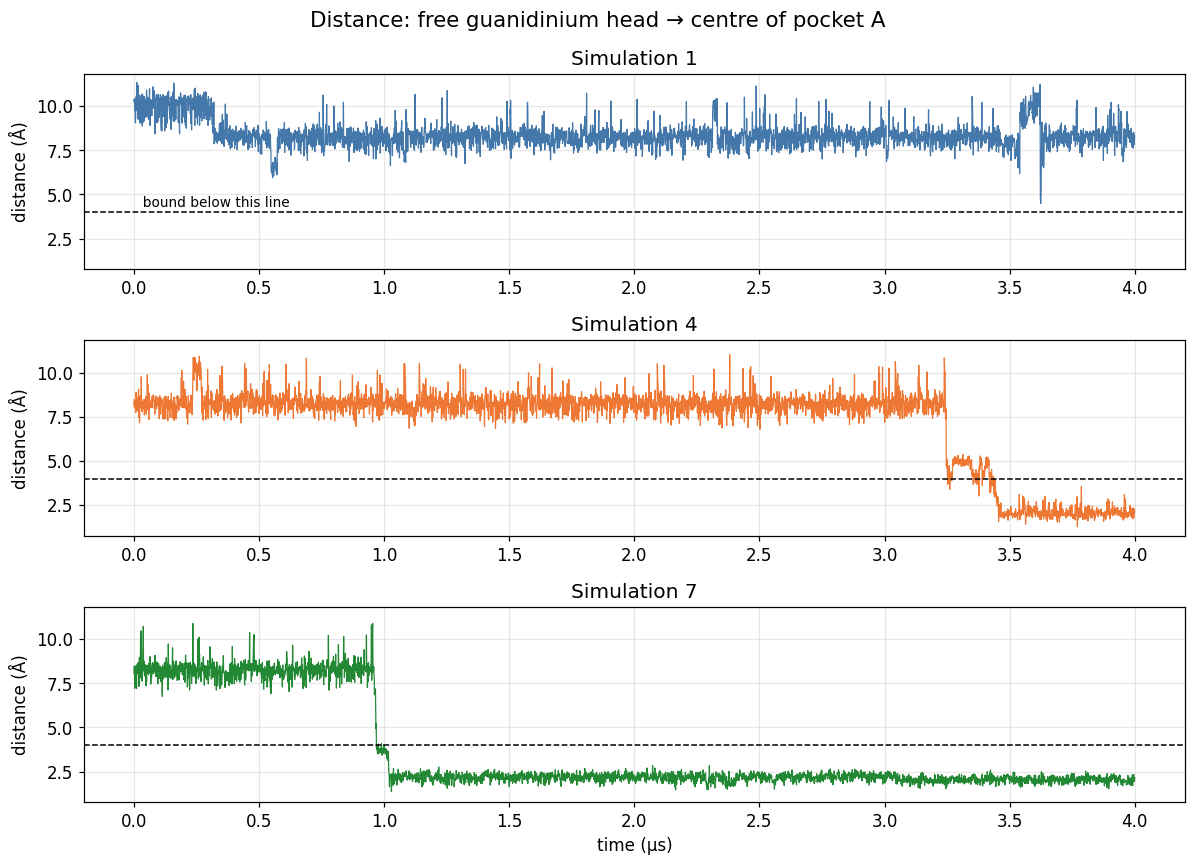

In [20]:
BOUND_CUTOFF = 4.0        # Å — below this the head sits inside the pocket

fig, axes = plt.subplots(3, 1, figsize=(11, 8), sharex=False, sharey=True)

for ax, (name, group), color in zip(axes, frames.groupby("simulation", sort=False), SIM_COLORS):
    ax.plot(group["time_us"], group["d_head_pocket"], lw=0.8, color=color)
    ax.axhline(BOUND_CUTOFF, ls="--", color="black", lw=1)
    ax.set_title(name)
    ax.set_ylabel("distance (Å)")

axes[0].text(frames["time_us"].min(), BOUND_CUTOFF + 0.3, "  bound below this line", fontsize=9)
axes[-1].set_xlabel("time (µs)")
fig.suptitle("Distance: free guanidinium head → centre of pocket A", fontsize=14)
plt.tight_layout()
plt.show()

### Exercise 3 — When exactly does the ligand bind?

Reading a binding time off a plot is imprecise. Write code that, for each simulation, reports

* whether the free head is ever closer than `BOUND_CUTOFF` to the pocket,
* the first frame **after which it stays bound** until the end of the trajectory,
* and the corresponding simulation time in µs.

<details>
<summary>🔍 Click here for the solution</summary>

```python
for name, group in frames.groupby("simulation", sort=False):
    bound = (group["d_head_pocket"] < BOUND_CUTOFF).values
    if not bound.any():
        print(f"{name}: never binds (closest approach {group['d_head_pocket'].min():.1f} Å)")
        continue
    last_unbound = np.where(~bound)[0].max()          # last frame that is NOT bound
    row = group.iloc[last_unbound + 1]
    print(f"{name}: bound in {bound.mean()*100:4.1f} % of all frames | "
          f"permanently bound from frame {int(row['frame'])} (t = {row['time_us']:.3f} µs)")
```

**What you should get:**

| simulation | bound frames | binding time |
|---|---|---|
| Simulation 1 | 0 % (closest approach 4.5 Å) | — |
| Simulation 4 | 15 % | 3.435 µs |
| Simulation 7 | 76 % | 0.999 µs |

Note how the two binding simulations differ: in Simulation 7 the ligand binds early and stays
bound, while in Simulation 4 it visits the pocket several times before the final binding event
near the end of the trajectory. Spontaneous binding events like these are rare — this is why the
published study needed many microseconds of simulation.

</details>

## Watch the binding event in 3D

Now that we know *when* binding happens, we can simply look at it. The cell below writes a short
window of Simulation 7 around the binding event into a multi-model PDB and animates it.

The frames are aligned on the pocket of chain A, so the pocket (green) stays still and you see the
**ligand** move into it. Chain B, on the other side, holds the other guanidinium head throughout —
watch how little it moves while the free head searches.

In [21]:
# A separate Universe, so that aligning for the movie does not disturb the analysis above.
u_movie = mda.Universe(PDB_FILE, XTC_FILES[2], in_memory=True)
align.AlignTraj(u_movie, reference, select="segid A and resid 6 7 8 9 10 11 12 and not name H*",
                in_memory=True).run()

# Both RNA chains and the ligand. The hydrogens of the RNA are left out of the file — they are
# not drawn anyway — which keeps the animation about half the size.
movie_atoms = u_movie.select_atoms("not (nucleic and name H*)")
movie_pdb = to_pdb_frames(movie_atoms, start=940, stop=1100, step=4)
print(f"{movie_pdb.count('MODEL ')} frames in the animation "
      f"(frames 940–1100 of Simulation 7, i.e. t ≈ 0.94–1.10 µs)")

show(movie_pdb, animate=True,
     highlight={"chain": "A", "resi": [7, 8, 9, 10]},
     zoom_on={"chain": "A", "resi": [6, 7, 8, 9, 10, 11, 12]})

40 frames in the animation (frames 940–1100 of Simulation 7, i.e. t ≈ 0.94–1.10 µs)


3Dmol.js failed to load for some reason. Please check your browser console for error messages.

## Hydrogen bonds between the ligand and the RNA

**Hydrogen bonds** are what actually holds the guanidinium group in the pocket. Counting them over
time tells us when specific interactions form — and *which* RNA atoms are involved.

A hydrogen bond is defined geometrically, by a **donor–acceptor distance** and a
**donor–hydrogen–acceptor angle**. The usual values are 3.5 Å and 150°; using a much larger
distance (say 10 Å) would count pairs of atoms that are nowhere near hydrogen-bonded.

For us:

* **donors** — the nitrogen atoms of the *free* guanidinium head (N1, N2, N6) and their hydrogens
* **acceptors** — the oxygens and the non-protonated nitrogens of the RNA

In [22]:
hbond_tables = []

for u, name in zip(universes, SIM_NAMES):
    print(f"Analysing hydrogen bonds in {name} ...")
    hbonds = HydrogenBondAnalysis(
        universe=u,
        donors_sel=FREE_HEAD,                 # N1, N2, N6 (and C1, which has no hydrogen)
        hydrogens_sel=FREE_HEAD_H,            # the hydrogens bonded to them
        acceptors_sel="nucleic and (name O* or name N1 or name N3 or name N7)",
        d_a_cutoff=3.5,                       # donor–acceptor distance (Å)
        d_h_a_angle_cutoff=150,               # donor–hydrogen–acceptor angle (degrees)
    )
    hbonds.run(verbose=True)

    result = hbonds.results.hbonds            # columns: frame, donor, hydrogen, acceptor, dist, angle
    acceptors = u.atoms[result[:, 3].astype(int)]
    hbond_tables.append(pd.DataFrame({
        "simulation": name,
        "frame": result[:, 0].astype(int),
        "acceptor": [f"{a.segid}:{a.resname}{a.resid} {a.name}" for a in acceptors],
    }))

hbond_df = pd.concat(hbond_tables, ignore_index=True)

# number of hydrogen bonds per frame -> new column of the `frames` table
counts = hbond_df.groupby(["simulation", "frame"]).size().rename("n_hbonds").reset_index()
frames = frames.merge(counts, on=["simulation", "frame"], how="left")
frames["n_hbonds"] = frames["n_hbonds"].fillna(0)

print("\nMost frequent hydrogen bond partners:")
print(hbond_df.groupby(["simulation", "acceptor"]).size()
      .groupby(level=0, group_keys=False).nlargest(5).to_string())

Analysing hydrogen bonds in Simulation 1 ...


  0%|          | 0/4001 [00:00<?, ?it/s]

Analysing hydrogen bonds in Simulation 4 ...


  0%|          | 0/4001 [00:00<?, ?it/s]

Analysing hydrogen bonds in Simulation 7 ...


  0%|          | 0/4001 [00:00<?, ?it/s]


Most frequent hydrogen bond partners:
simulation    acceptor
Simulation 1  A:A8 O1P    2498
              A:A8 O2P    2279
              B:A8 O2P     381
              B:A8 O1P     379
              B:G7 O2'     171
Simulation 4  A:A8 O1P    2846
              A:A8 O2P    2011
              A:C9 O2P     478
              A:A8 O5'     229
              A:G10 N7     169
Simulation 7  A:A8 O1P    3525
              A:C9 O2P    2952
              A:G10 O6    2682
              A:G10 N7    2424
              A:A8 O2P     625


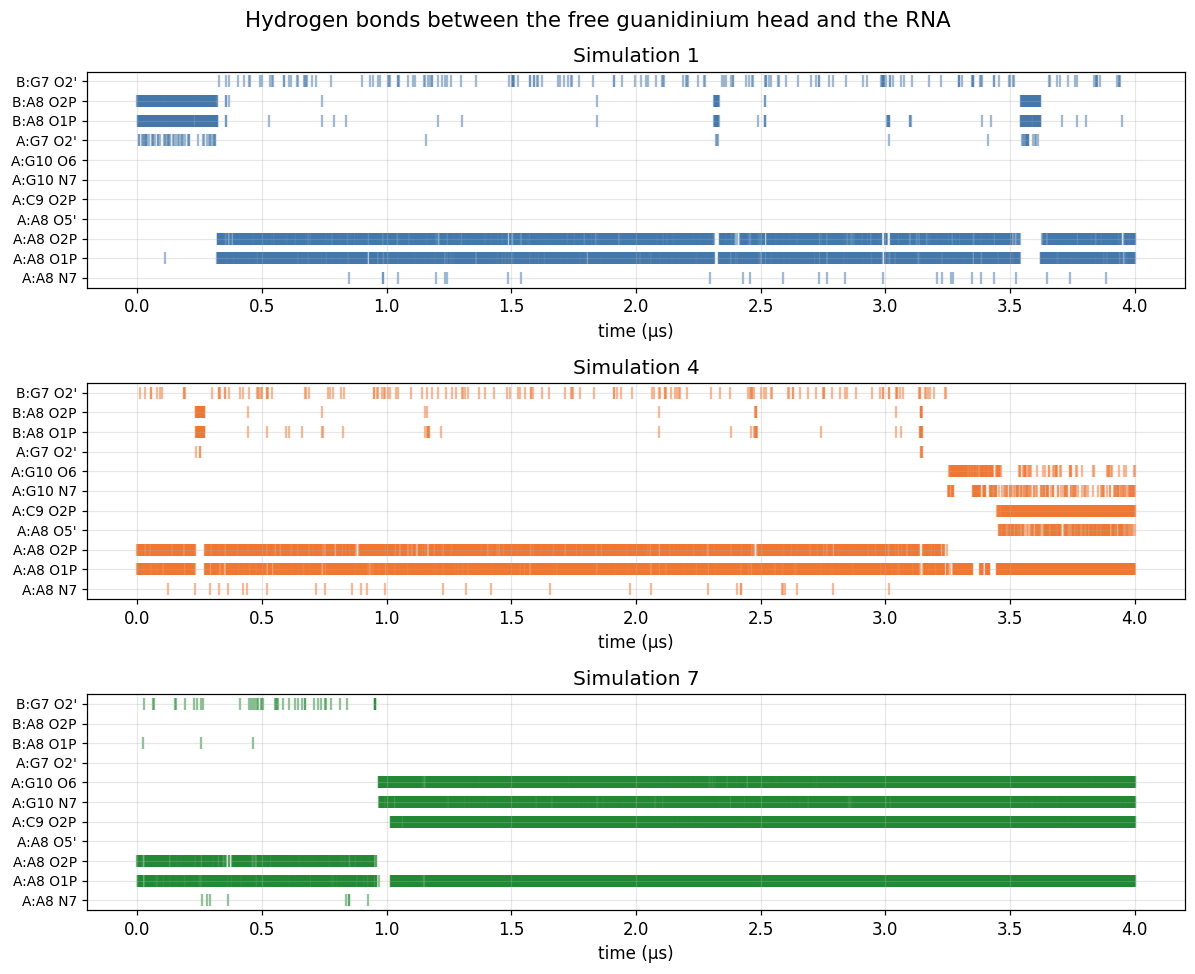

In [23]:
# Which RNA atoms are contacted, and when? (a "hydrogen bond fingerprint")
frequent = hbond_df["acceptor"].value_counts()
frequent = frequent[frequent > 50].index.tolist()        # ignore very rare contacts
order = {name: i for i, name in enumerate(sorted(frequent))}

fig, axes = plt.subplots(3, 1, figsize=(11, 9), sharey=True)

for ax, name, color in zip(axes, SIM_NAMES, SIM_COLORS):
    subset = hbond_df[(hbond_df["simulation"] == name) & (hbond_df["acceptor"].isin(frequent))]
    times = frames.loc[frames["simulation"] == name].set_index("frame")["time_us"]
    ax.scatter(times.loc[subset["frame"]].values,
               subset["acceptor"].map(order).values,
               marker="|", s=60, color=color, alpha=0.5)
    ax.set_yticks(range(len(order)))
    ax.set_yticklabels(sorted(frequent), fontsize=9)
    ax.set_title(name)
    ax.set_xlabel("time (µs)")

fig.suptitle("Hydrogen bonds between the free guanidinium head and the RNA", fontsize=14)
plt.tight_layout()
plt.show()

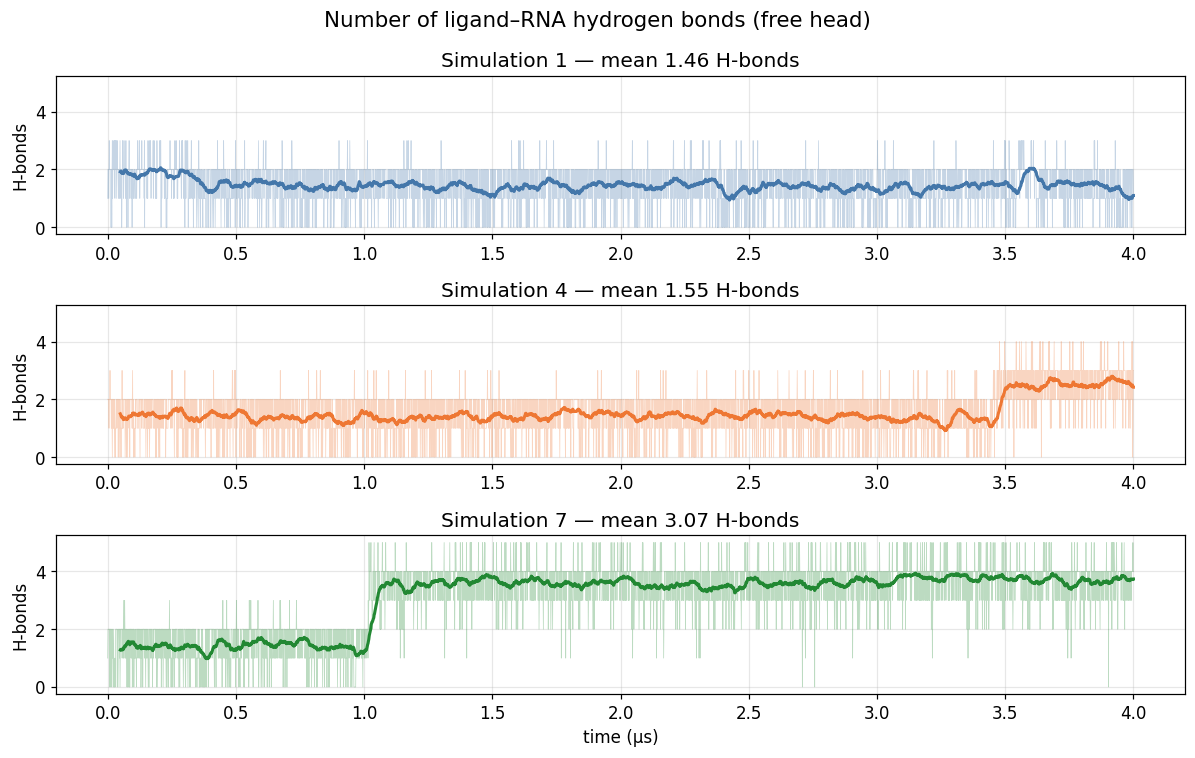

In [24]:
fig, axes = plt.subplots(3, 1, figsize=(11, 7), sharey=True)

for ax, (name, group), color in zip(axes, frames.groupby("simulation", sort=False), SIM_COLORS):
    ax.plot(group["time_us"], group["n_hbonds"], lw=0.5, alpha=0.3, color=color)
    ax.plot(group["time_us"].values[49:], running_average(group["n_hbonds"].values, 50),
            lw=2, color=color)
    ax.set_title(f"{name} — mean {group['n_hbonds'].mean():.2f} H-bonds")
    ax.set_ylabel("H-bonds")

axes[-1].set_xlabel("time (µs)")
fig.suptitle("Number of ligand–RNA hydrogen bonds (free head)", fontsize=14)
plt.tight_layout()
plt.show()

### Question 2 — Reading the hydrogen bond fingerprint

Compare the three fingerprint plots.

1. Which RNA atoms does the free guanidinium head contact in Simulation 1?
2. Which additional partners appear in Simulations 4 and 7, and at which time?
3. Why is the *identity* of the partners more informative than the *number* of hydrogen bonds?

<details>
<summary>🔍 Click here for a discussion of the answer</summary>

1. In Simulation 1 the head only makes short-lived contacts with the **phosphate oxygens of A8**,
   in both chains. These are unspecific electrostatic contacts: a positively charged guanidinium
   group sticking to the negatively charged backbone, anywhere along it.
2. In Simulations 4 and 7 a characteristic set appears and then persists: **A:A8 O1P, A:C9 O2P**
   together with **A:G10 O6 and A:G10 N7** — the Hoogsteen edge of G10 plus two backbone
   phosphates. These contacts switch on exactly at the binding times you determined in Exercise 3
   (≈ 3.4 µs and ≈ 1.0 µs) and stay on afterwards. That combination *is* the bound state.
3. Because the count alone cannot distinguish "stuck somewhere on the backbone" from "bound in the
   pocket" — in both cases the guanidinium makes 1–3 hydrogen bonds. Only the **pattern** of
   partners identifies the binding site. This is also how experimental mutagenesis targets a
   binding site: mutate G10 and the ligand should no longer bind specifically.

</details>

## How much surface is buried on binding?

A complementary, purely geometric way to detect binding: when the guanidinium head docks into the
pocket, the surface it shares with the RNA is no longer accessible to water. The **buried surface
area** is

```
buried = SASA(RNA) + SASA(head) − SASA(RNA + head)
```

and it is a standard measure of how large a molecular interface is.

Calculating buried surface area for Simulation 1 ...
Calculating buried surface area for Simulation 4 ...
Calculating buried surface area for Simulation 7 ...


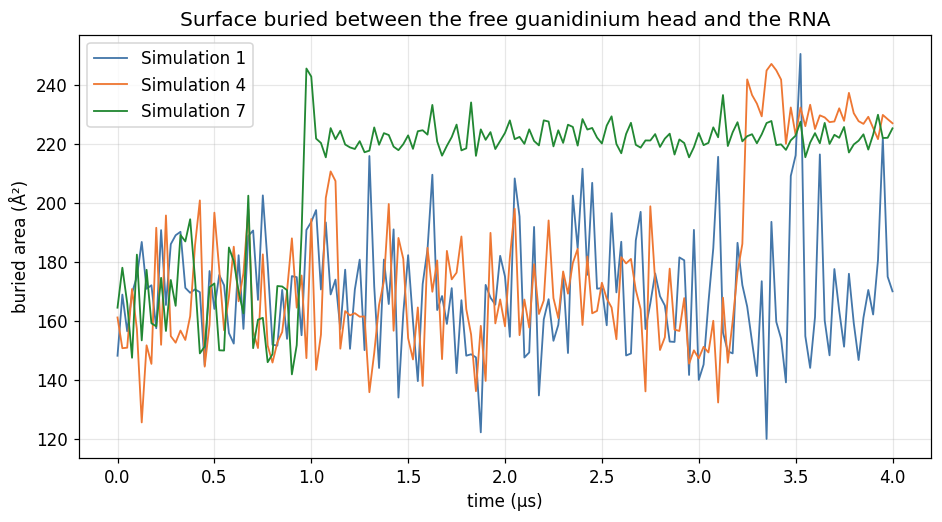

unbound frames: 169 ± 21 Å²
bound frames:   224 ± 6 Å²


In [25]:
STEP_SASA = 25           # three SASA runs per simulation — keep the step size large

buried_results = {}
for u, name in zip(universes, SIM_NAMES):
    print(f"Calculating buried surface area for {name} ...")
    with quiet():
        sasa_rna = SASAAnalysis(u.select_atoms(RNA)).run(step=STEP_SASA)
        sasa_head = SASAAnalysis(u.select_atoms(f"({FREE_HEAD}) or ({FREE_HEAD_H})")).run(step=STEP_SASA)
        sasa_both = SASAAnalysis(u.select_atoms(f"{RNA} or ({FREE_HEAD}) or ({FREE_HEAD_H})")).run(step=STEP_SASA)
    buried_results[name] = (np.asarray(sasa_rna.results.total_area)
                            + np.asarray(sasa_head.results.total_area)
                            - np.asarray(sasa_both.results.total_area))

plt.figure()
for (name, buried), color in zip(buried_results.items(), SIM_COLORS):
    time_us = frames.loc[frames["simulation"] == name, "time_us"].values[::STEP_SASA][:len(buried)]
    plt.plot(time_us, buried, lw=1.2, color=color, label=name)

plt.title("Surface buried between the free guanidinium head and the RNA")
plt.xlabel("time (µs)")
plt.ylabel("buried area (Å²)")
plt.legend()
plt.show()

# How much surface does binding actually bury? Compare bound and unbound frames.
buried_all = np.concatenate([buried_results[name] for name in SIM_NAMES])
distance_all = np.concatenate([frames.loc[frames["simulation"] == name, "d_head_pocket"]
                               .values[::STEP_SASA][:len(buried_results[name])]
                               for name in SIM_NAMES])
is_bound = distance_all < BOUND_CUTOFF

print(f"unbound frames: {buried_all[~is_bound].mean():.0f} ± {buried_all[~is_bound].std():.0f} Å²")
print(f"bound frames:   {buried_all[is_bound].mean():.0f} ± {buried_all[is_bound].std():.0f} Å²")

Note that the buried area never drops to zero: the ligand is **tethered** to the RNA by its other
head, so the free guanidinium always lies somewhere on the RNA surface. That gives a baseline of
roughly 170 Å². Binding adds about **55 Å²** on top of it — the area of one guanidinium face
pressed against the pocket.

Just as telling is the *spread*: ±21 Å² while the head wanders over the surface, but only ±6 Å²
once it is bound. A rigid, reproducible interface is what distinguishes a real binding site from
an unspecific contact.

# Dimensionality Reduction and Clustering

To analyze a molecule's movements, we first describe its 3D shape using numerical features called descriptors. These descriptors ignore the molecule's overall tumbling and focus only on the internal changes in its structure.

**Dihedral Angles**
Dihedral angles are a simple descriptor that measures the twists in a protein's backbone. They are excellent for capturing the fundamental folding and flexibility of the protein chain.

**Pairwise Distances**
Pairwise distances describe the distances between different atoms or parts of the molecule. This provides a more detailed, global picture of the molecule's overall shape and how its different regions move closer together or further apart.

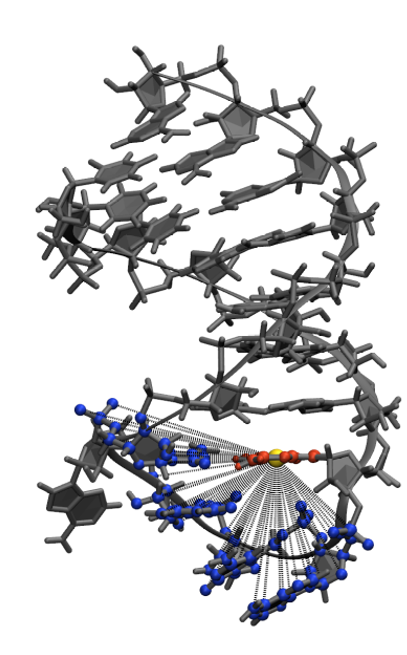

Pairwise distances between atoms surrounding a ligand binding pocket (blue) and a reference point (yellow).

From: Steuer, J., Kukharenko, O., Riedmiller, K., Hartig, J. S., & Peter, C. (2021). Guanidine-II aptamer conformations and ligand binding modes through the lens of molecular simulation. Nucleic Acids Research, 49(14), 7954–7965. https://doi.org/10.1093/nar/gkab592


## Principal Component Analysis (PCA)

**PCA** is a powerful technique used to identify the dominant, large-scale motions in a simulation.
It reduces the complex, high-dimensional movements of all atoms into a few "principal components" (PCs) that describe the most significant collective motions.

For example, PC1 might describe a hinge-like opening and closing of two domains, while PC2 describes a twisting motion.

By projecting the trajectory onto the first two PCs (PC1 and PC2), we can create a 2D map of the molecule's "conformational landscape."

Clusters in the plot represent stable or semi-stable conformational states.

Paths between clusters represent transitions from one state to another.



<img src="https://media.geeksforgeeks.org/wp-content/uploads/20250526125548648108/What-is-Dimensionality-Reduction-.webp" width="60%">

From: https://www.geeksforgeeks.org/machine-learning/dimensionality-reduction/




<img src="https://numxl.com/wp-content/uploads/principal-component-analysis-pca-featured.png" width="60%">

From: https://numxl.com/blogs/principal-component-analysis-pca-101/


### Choosing the features

We describe each frame by the **pairwise distances** between a set of RNA atoms and the ligand
atoms. One practical point that matters on Colab: using *all* RNA atoms against *all* ligand atoms
would give 1166 × 30 ≈ 35 000 numbers per frame, i.e. several gigabytes for 12 000 frames.

A representative subset of the RNA — the phosphorus atom, the sugar C1′ and the base nitrogen N1 /
N9 of every nucleotide — captures the position and orientation of the ligand just as well, in a
matrix roughly 20 times smaller.

In [26]:
RNA_REPRESENTATIVE = "nucleic and (name P or name C1' or name N1 or name N9)"
LIGAND_HEAVY = "resname BGD and not name H*"


def distance_features(universe, selection_a, selection_b, desc=""):
    """All pairwise distances between two selections, for every frame: one row per frame."""
    group_a = universe.select_atoms(selection_a)
    group_b = universe.select_atoms(selection_b)
    features = np.empty((universe.trajectory.n_frames, group_a.n_atoms * group_b.n_atoms),
                        dtype=np.float32)
    for i, _ in enumerate(tqdm(universe.trajectory, desc=desc, leave=False)):
        features[i] = mdadist.distance_array(group_a.positions, group_b.positions).ravel()
    return features


print("Calculating pairwise distances ...")
global_features = np.vstack([distance_features(u, RNA_REPRESENTATIVE, LIGAND_HEAVY, name)
                             for u, name in zip(universes, SIM_NAMES)])
print(f"feature matrix: {global_features.shape[0]} frames × {global_features.shape[1]} distances "
      f"({global_features.nbytes / 1e6:.0f} MB)")

global_pca = PCA(n_components=2).fit(global_features)
global_projection = global_pca.transform(global_features)
frames["PC1_global"], frames["PC2_global"] = global_projection[:, 0], global_projection[:, 1]

print("explained variance:", (global_pca.explained_variance_ratio_ * 100).round(1), "%")

Calculating pairwise distances ...


Simulation 1:   0%|          | 0/4001 [00:00<?, ?it/s]

Simulation 4:   0%|          | 0/4001 [00:00<?, ?it/s]

Simulation 7:   0%|          | 0/4001 [00:00<?, ?it/s]

feature matrix: 12003 frames × 1512 distances (73 MB)
explained variance: [68.9  6.8] %


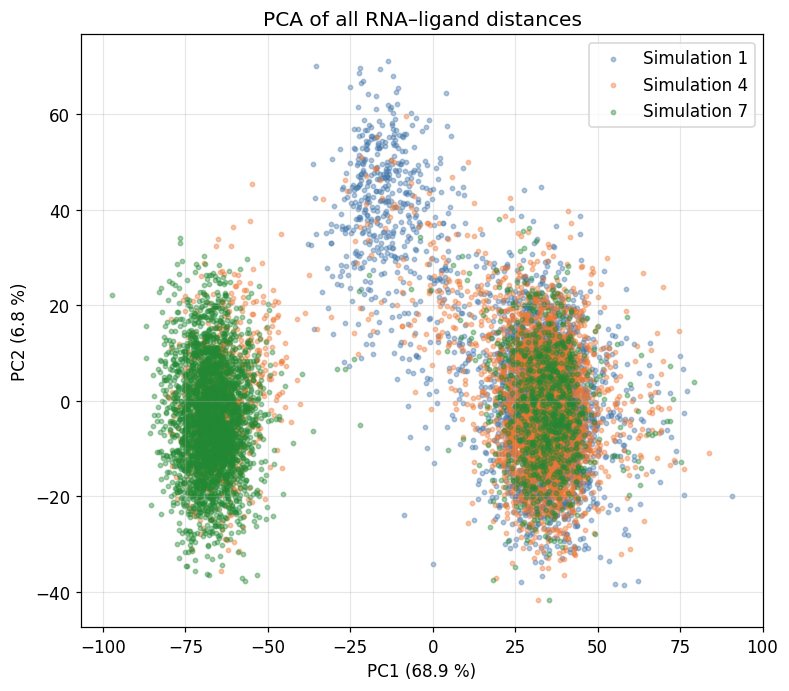

In [27]:
plt.figure(figsize=(8, 7))
for (name, group), color in zip(frames.groupby("simulation", sort=False), SIM_COLORS):
    plt.scatter(group["PC1_global"], group["PC2_global"], s=8, alpha=0.4, color=color, label=name)

plt.title("PCA of all RNA–ligand distances")
plt.xlabel(f"PC1 ({global_pca.explained_variance_ratio_[0]*100:.1f} %)")
plt.ylabel(f"PC2 ({global_pca.explained_variance_ratio_[1]*100:.1f} %)")
plt.legend()
plt.show()

### Zooming in: a PCA of the binding site only

The map above describes the ligand with respect to the *whole* RNA. If we are interested in the
binding event itself, it is better to use features that only describe the **free head** and the
**pocket it binds to**. Here the hydrogens of the guanidinium group are included on purpose — as
we will see, they distinguish two different ways of sitting in the pocket.

Simulation 1:   0%|          | 0/4001 [00:00<?, ?it/s]

Simulation 4:   0%|          | 0/4001 [00:00<?, ?it/s]

Simulation 7:   0%|          | 0/4001 [00:00<?, ?it/s]

feature matrix: 1467 distances per frame
explained variance: [85.2  8.1] %


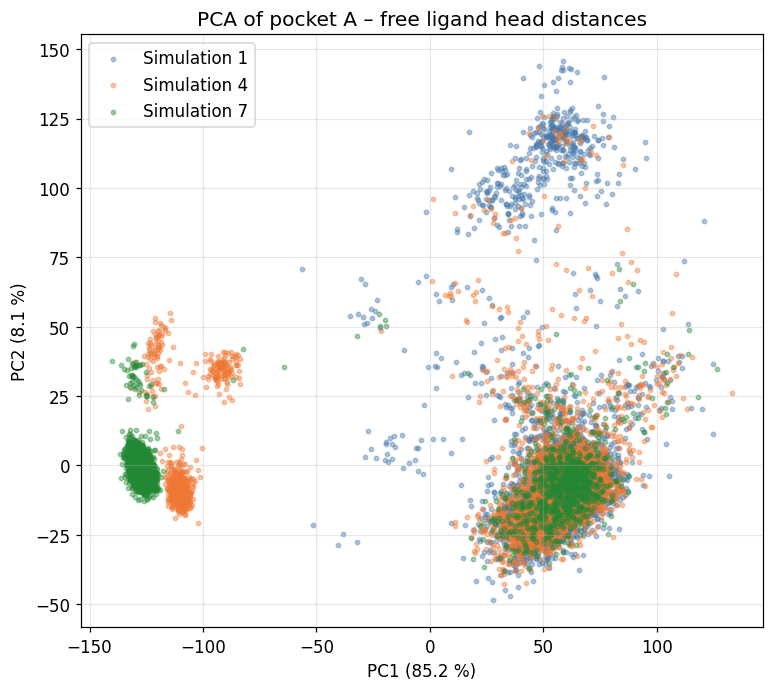

In [28]:
POCKET_A_WIDE = "segid A and resid 7 8 9 10 12"

pocket_features = np.vstack([
    distance_features(u, POCKET_A_WIDE, f"({FREE_HEAD}) or ({FREE_HEAD_H})", name)
    for u, name in zip(universes, SIM_NAMES)])

pocket_pca = PCA(n_components=2).fit(pocket_features)
pocket_projection = pocket_pca.transform(pocket_features)
frames["PC1"], frames["PC2"] = pocket_projection[:, 0], pocket_projection[:, 1]

print(f"feature matrix: {pocket_features.shape[1]} distances per frame")
print("explained variance:", (pocket_pca.explained_variance_ratio_ * 100).round(1), "%")

plt.figure(figsize=(8, 7))
for (name, group), color in zip(frames.groupby("simulation", sort=False), SIM_COLORS):
    plt.scatter(group["PC1"], group["PC2"], s=8, alpha=0.4, color=color, label=name)

plt.title("PCA of pocket A – free ligand head distances")
plt.xlabel(f"PC1 ({pocket_pca.explained_variance_ratio_[0]*100:.1f} %)")
plt.ylabel(f"PC2 ({pocket_pca.explained_variance_ratio_[1]*100:.1f} %)")
plt.legend()
plt.show()

### Question 3 — Comparing the two maps

What changed between the two 2D maps? Which one would you use to study the binding event, and
why?

<details>
<summary>🔍 Click here for a discussion of the answer</summary>

The first map is dominated by where the ligand sits relative to the **whole** dimer; PC1 explains
about 69 % of the variance and the three simulations overlap in a single broad cloud.

The second map is built from distances that only change when the free head approaches **its**
pocket. PC1 now explains about 85 % of the variance and the data separate into a large unbound
region and one or more compact, well-separated bound regions — one of which is visited only by
Simulation 4 and another only by Simulation 7.

The lesson is general: a low-dimensional map is only as good as the features you put in. Choosing
features that are *specific to the process of interest* is usually more important than the choice
of the dimensionality reduction method.

</details>

## Clustering of the 2D Conformational Landscape

**Clustering** is a type of unsupervised machine learning where the goal is to find natural groupings in your data without any predefined labels.
Think of it like sorting a vast collection of photos into piles based on visual similarity—you don't know the categories beforehand, but you can see that certain photos belong together.

In molecular dynamics, we use clustering to simplify the complex motions of a trajectory.
The 2D PCA map you created shows the conformational landscape, and clustering helps us automatically identify the most populated regions, which correspond to the molecule's major conformational states.
Instead of analyzing thousands of individual frames, we can analyze just a few representative structures—one for each cluster—to understand the system's overall behavior.

We will use the HDBSCAN algorithm implemented in scikit-learn.

- **HDBSCAN**: A advanced, density-based algorithm that can find clusters of varying shapes and, importantly, does not require you to set the number of clusters beforehand. It can also identify points that don't belong to any cluster, labeling them as "noise."

In [29]:
labels = HDBSCAN(min_cluster_size=150).fit_predict(pocket_projection)
frames["cluster"] = labels

n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
print(f"HDBSCAN found {n_clusters} clusters "
      f"({(labels == -1).sum()} frames classified as noise)")

HDBSCAN found 4 clusters (638 frames classified as noise)


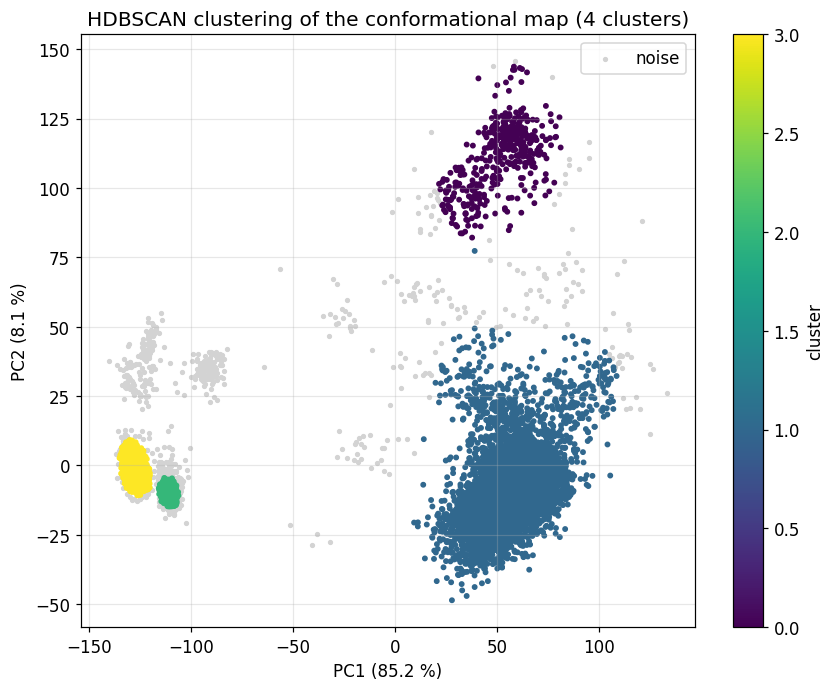

In [30]:
plt.figure(figsize=(9, 7))
noise = frames["cluster"] == -1
plt.scatter(frames.loc[noise, "PC1"], frames.loc[noise, "PC2"], s=6, color="lightgrey",
            label="noise")
scatter = plt.scatter(frames.loc[~noise, "PC1"], frames.loc[~noise, "PC2"],
                      c=frames.loc[~noise, "cluster"], cmap="viridis", s=8)
plt.colorbar(scatter, label="cluster")
plt.title(f"HDBSCAN clustering of the conformational map ({n_clusters} clusters)")
plt.xlabel(f"PC1 ({pocket_pca.explained_variance_ratio_[0]*100:.1f} %)")
plt.ylabel(f"PC2 ({pocket_pca.explained_variance_ratio_[1]*100:.1f} %)")
plt.legend()
plt.show()

A cluster is only useful once you know **what it means**. Because every descriptor lives in the
same table, we can simply average them per cluster:

In [31]:
summary = (frames[frames["cluster"] >= 0]
           .groupby("cluster")
           .agg(n_frames=("frame", "size"),
                head_to_pocket=("d_head_pocket", "mean"),
                h_bonds=("n_hbonds", "mean"),
                end_to_end=("d_end_to_end", "mean"),
                pocket_width=("pocket_width", "mean"))
           .round(2))

population = frames[frames["cluster"] >= 0].pivot_table(
    index="cluster", columns="simulation", values="frame", aggfunc="size", fill_value=0)

summary = summary.join(population)
summary["state"] = np.where(summary["head_to_pocket"] < 4, "BOUND", "unbound")
summary

,n_frames,head_to_pocket,h_bonds,end_to_end,pocket_width,Simulation 1,Simulation 4,Simulation 7,state
cluster,,,,,,,,,
0,429,10.01,1.90,6.71,7.25,386,43,0,unbound
1,7586,8.25,1.41,7.97,6.84,3484,3150,952,unbound
2,423,2.01,2.51,8.20,7.15,0,423,0,BOUND
3,2927,2.14,3.64,7.95,6.92,0,0,2927,BOUND


## Finding and Visualizing Cluster Centroids

A cluster is just a collection of points.
To make this chemically meaningful, we need to find the centroid—the actual simulation frame that is most representative of each cluster.
We can find this by identifying the frame closest to the geometric center of each cluster in our 2D PCA map.

Once we have the frame index for each centroid, we can use nglview to visualize its 3D structure.

In [32]:
def medoid_frame(cluster_id):
    """Index (row number of `frames`) of the frame closest to the centre of a cluster."""
    members = np.where(frames["cluster"].values == cluster_id)[0]
    coordinates = pocket_projection[members]
    centre = coordinates.mean(axis=0).reshape(1, -1)
    return members[int(np.argmin(euclidean_distances(coordinates, centre)))]


centroids = {}
for cluster_id in sorted(c for c in set(labels) if c >= 0):
    index = medoid_frame(cluster_id)
    row = frames.iloc[index]
    sim_index = SIM_NAMES.index(row["simulation"])
    universe = universes[sim_index]
    universe.trajectory[int(row["frame"])]

    filename = f"centroid_cluster_{cluster_id}.pdb"
    universe.atoms.write(filename)
    centroids[cluster_id] = filename
    print(f"cluster {cluster_id}: {row['simulation']}, frame {int(row['frame'])} "
          f"(t = {row['time_us']:.2f} µs), head–pocket distance {row['d_head_pocket']:.2f} Å "
          f"-> {filename}")

cluster 0: Simulation 4, frame 246 (t = 0.25 µs), head–pocket distance 10.01 Å -> centroid_cluster_0.pdb
cluster 1: Simulation 4, frame 1233 (t = 1.23 µs), head–pocket distance 8.28 Å -> centroid_cluster_1.pdb
cluster 2: Simulation 4, frame 3890 (t = 3.89 µs), head–pocket distance 2.03 Å -> centroid_cluster_2.pdb
cluster 3: Simulation 7, frame 1727 (t = 1.73 µs), head–pocket distance 2.19 Å -> centroid_cluster_3.pdb


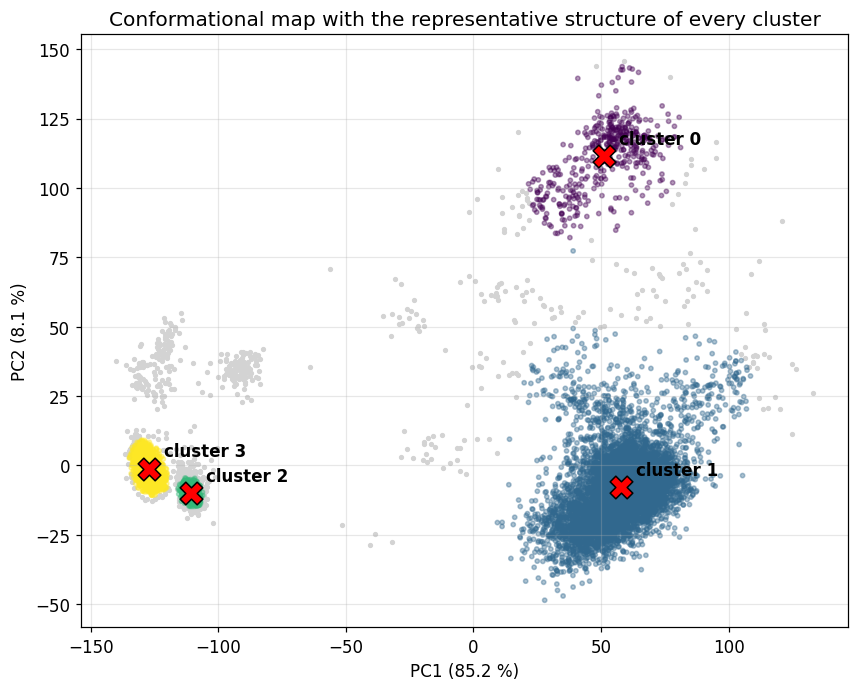

In [33]:
plt.figure(figsize=(9, 7))
plt.scatter(frames.loc[noise, "PC1"], frames.loc[noise, "PC2"], s=6, color="lightgrey")
plt.scatter(frames.loc[~noise, "PC1"], frames.loc[~noise, "PC2"],
            c=frames.loc[~noise, "cluster"], cmap="viridis", s=8, alpha=0.4)

for cluster_id in centroids:
    index = medoid_frame(cluster_id)
    plt.scatter(*pocket_projection[index], marker="X", s=220, c="red", edgecolor="black", zorder=5)
    plt.annotate(f"cluster {cluster_id}", pocket_projection[index],
                 textcoords="offset points", xytext=(10, 8), fontweight="bold")

plt.title("Conformational map with the representative structure of every cluster")
plt.xlabel(f"PC1 ({pocket_pca.explained_variance_ratio_[0]*100:.1f} %)")
plt.ylabel(f"PC2 ({pocket_pca.explained_variance_ratio_[1]*100:.1f} %)")
plt.show()

Each of these representative structures was written to a PDB file, so we can look at them one by
one. The second view keeps only the ligand and the pocket and draws them as sticks with all
hydrogens — the close-up you need to judge a binding pose.

**Change `CLUSTER_TO_SHOW` and re-run both cells for every cluster in the table above.** Use the
`head_to_pocket` column to predict what you will see before you look.

In [42]:
CLUSTER_TO_SHOW = sorted(centroids)[0]
centroid = mda.Universe(centroids[CLUSTER_TO_SHOW])
print(f"cluster {CLUSTER_TO_SHOW}: {centroids[CLUSTER_TO_SHOW]}")

show(centroid.atoms,
     highlight={"chain": "A", "resi": [7, 8, 9, 10]},
     zoom_on={"chain": "A", "resi": [6, 7, 8, 9, 10, 11, 12]})

cluster 0: centroid_cluster_0.pdb


3Dmol.js failed to load for some reason. Please check your browser console for error messages.

In [41]:
binding_site = centroid.select_atoms(f"{LIGAND} or ({POCKET_A})")

show(binding_site, style="sticks", hydrogens="all",
     highlight={"chain": "A", "resi": [10]}, height=460)

3Dmol.js failed to load for some reason. Please check your browser console for error messages.

### Exercise 4 — The two bound states

The cluster table shows **two** clusters in which the free head sits inside pocket A
(head–pocket distance ≈ 2 Å), and each of them is populated by only one of the two binding
simulations. So the ligand apparently found *two different ways* of sitting in the same pocket.

1. Find the two bound clusters automatically (do not hard-code the cluster numbers).
2. Look at both representative structures in 3D, zoomed in on the pocket and with the hydrogens
   shown (`hydrogens="all"`). The difference is in where the N–H groups point, so without the
   hydrogens you cannot see it at all.
3. Find a single distance that distinguishes the two states, and verify it numerically.

<details>
<summary>🔍 Click here for the solution</summary>

```python
bound_clusters = summary.index[summary["state"] == "BOUND"].tolist()
print("bound clusters:", bound_clusters)

# 2 — a close-up of the binding site: load the saved structure, keep only the ligand and the
#     pocket, and draw everything as sticks with all hydrogens. G10 is highlighted in green.
for cluster_id in bound_clusters:
    centroid = mda.Universe(centroids[cluster_id])
    site = centroid.select_atoms(f"{LIGAND} or ({POCKET_A})")
    print(f"cluster {cluster_id}")
    display(show(site, style="sticks", hydrogens="all",
                 highlight={"chain": "A", "resi": [10]}, height=440))

# 3 — the guanidinium group is rotated: a different N–H points at the Hoogsteen edge of G10.
#     The linker nitrogen N2 is a convenient probe.
frames["d_N2_G10"] = distance_per_frame("resname BGD and name N2",
                                        "segid A and resid 10 and name O6", "N2 → G10 O6")

print(frames[frames["cluster"].isin(bound_clusters)]
      .groupby("cluster")["d_N2_G10"].agg(["mean", "std"]).round(2))
```

**What you should see:** the two bound clusters give clearly different values — roughly **4.4 Å**
in one and **3.0 Å** in the other. The guanidinium group is **rotated** in the pocket, so that a
different pair of N–H groups points at the Hoogsteen edge (O6/N7) of G10.

The hydrogen bond fingerprints tell the same story. Restricted to the bound part of each
trajectory, the occupancies are

| contact | Simulation 4 mode | Simulation 7 mode |
|---|---|---|
| A:A8 O1P | 0.90 | 0.95 |
| A:C9 O2P | 0.84 | 0.98 |
| A:A8 O5′ | 0.40 | – |
| A:G10 N7 | 0.21 | 0.80 |
| A:G10 O6 | 0.10 | 0.88 |

Both modes clamp the same two backbone phosphates, but only the Simulation 7 mode engages G10
properly — which is also why the cluster table gives it 3.6 hydrogen bonds on average against 2.5.
The Simulation 4 mode is the shallower, more backbone-dominated pose.

Distinct binding modes of this kind — differing in how the guanidinium group is rotated inside the
pocket — are discussed in Figure 4 of Steuer *et al.* (2024),
*NAR Genomics and Bioinformatics* **6**(3). Note that the exact number of clusters and their
numbering depend on the features and on `min_cluster_size`, so do not expect a one-to-one match
with the figure in the paper.

A fair warning, and a good discussion point: each of the two modes is seen in only *one*
simulation. With a sample size of one trajectory per mode we cannot say anything about their
relative free energies — only that both are accessible.

</details>

## Interpreting the PCA Map

By coloring the low-dimensional map according to meaningful descriptors, we can obtain a better understanding of the studied system.

Every descriptor we computed is a column of `frames`, and the rows are in the same order as the
PCA projection. Colouring the map by any of them is therefore a one-liner.

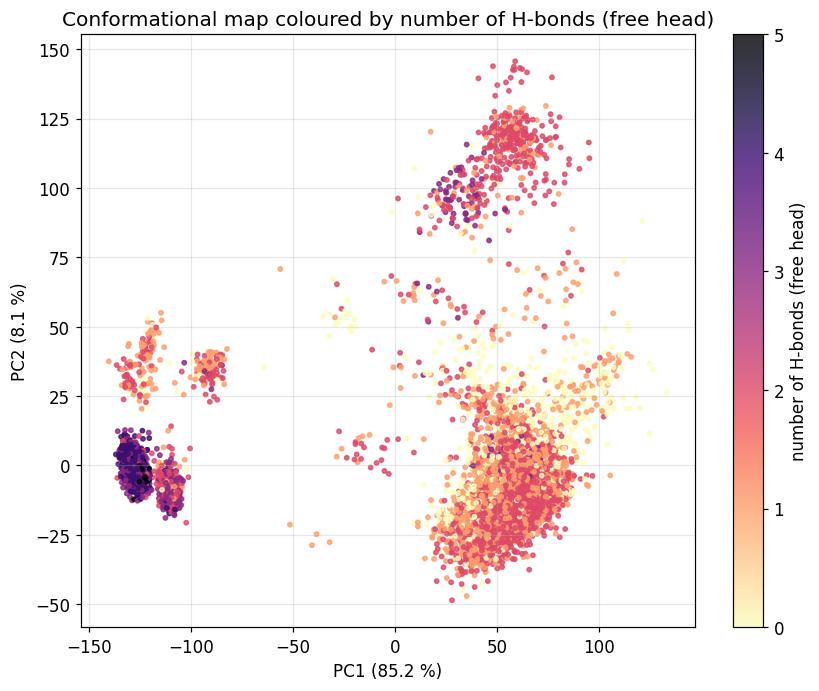

In [36]:
def color_map_by(column, label, cmap="viridis", ax=None):
    """Scatter the conformational map, coloured by one column of the `frames` table."""
    ax = ax or plt.gca()
    scatter = ax.scatter(frames["PC1"], frames["PC2"], c=frames[column], cmap=cmap, s=8, alpha=0.8)
    plt.colorbar(scatter, ax=ax, label=label)
    ax.set_title(f"Conformational map coloured by {label}")
    ax.set_xlabel(f"PC1 ({pocket_pca.explained_variance_ratio_[0]*100:.1f} %)")
    ax.set_ylabel(f"PC2 ({pocket_pca.explained_variance_ratio_[1]*100:.1f} %)")
    return scatter


plt.figure(figsize=(9, 7))
color_map_by("n_hbonds", "number of H-bonds (free head)", cmap="magma_r")
plt.show()

### The end-to-end distance of the ligand

How stretched or bent is the ligand in the different states? The distance between its two
guanidinium carbons (C1 and C6) answers that — we already stored it as `d_end_to_end`.

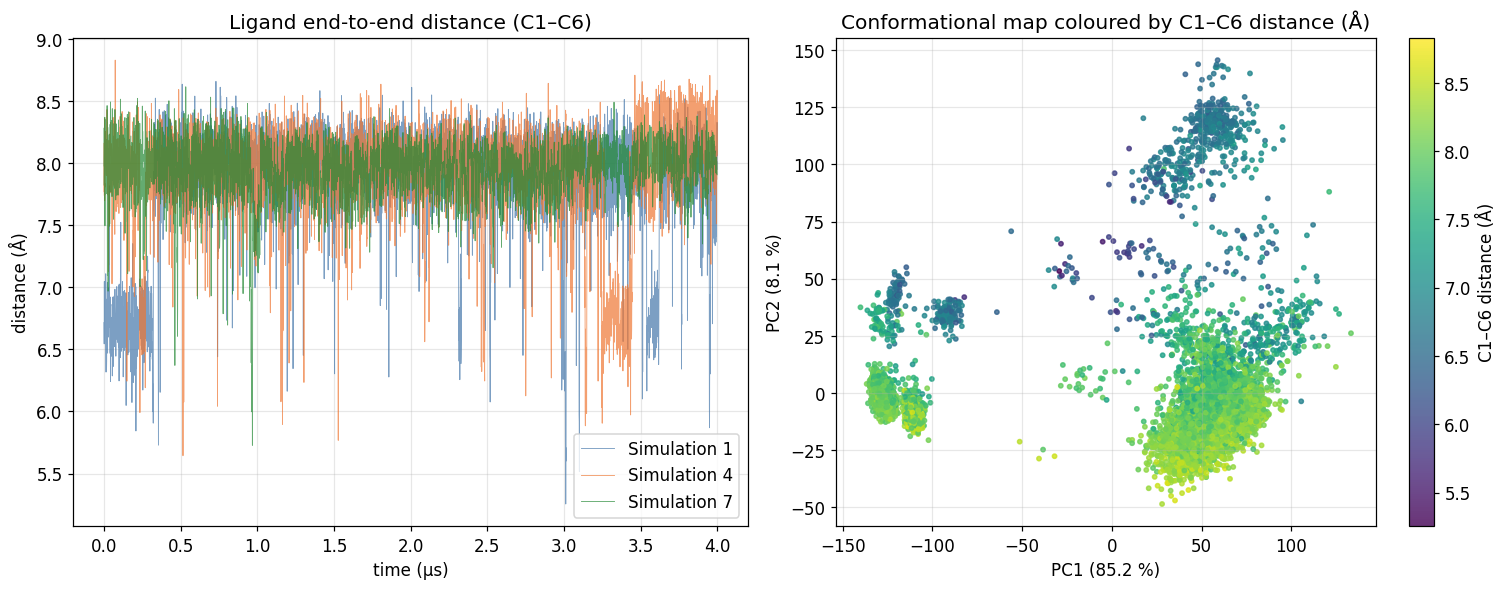

In [37]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

for (name, group), color in zip(frames.groupby("simulation", sort=False), SIM_COLORS):
    axes[0].plot(group["time_us"], group["d_end_to_end"], lw=0.6, alpha=0.7, color=color, label=name)
axes[0].set_title("Ligand end-to-end distance (C1–C6)")
axes[0].set_xlabel("time (µs)")
axes[0].set_ylabel("distance (Å)")
axes[0].legend()

color_map_by("d_end_to_end", "C1–C6 distance (Å)", ax=axes[1])

plt.tight_layout()
plt.show()

### Exercise 5 — Colour the map by the width of the pocket entrance

`frames["pocket_width"]` is the distance between the phosphate oxygen O1P of A8 and O6 of G10,
i.e. how wide the entrance of pocket A is. Colour the conformational map by it.

Does the pocket have to open up for the ligand to enter?

<details>
<summary>🔍 Click here for the solution</summary>

```python
plt.figure(figsize=(9, 7))
color_map_by("pocket_width", "width of the pocket entrance (Å)", cmap="cividis")
plt.show()

print(frames.groupby(frames["d_head_pocket"] < BOUND_CUTOFF)["pocket_width"]
      .agg(["mean", "std"]).round(2))
```

**What you should see:** very little structure — the colours are mixed everywhere and the mean
pocket width is practically identical in the bound and unbound frames (≈ 6.9 Å both times, with a
spread of ±0.4 Å). The binding site is **pre-organised**: it does not have to open to accept the
ligand. That is a genuine (and useful) negative result — not every descriptor you try will
correlate with the process you study, and reporting the ones that do not is part of an honest
analysis.

</details>

### Exercise 6 — Colour the map by the ligand–pocket distance

Do the same with `d_head_pocket`, and compare the picture with the cluster plot.

<details>
<summary>🔍 Click here for the solution</summary>

```python
plt.figure(figsize=(9, 7))
color_map_by("d_head_pocket", "free head → pocket A distance (Å)", cmap="viridis_r")
plt.show()
```

**What you should see:** a clean gradient along PC1 — the first principal component essentially
*is* the binding coordinate. The bound clusters sit at one end of the map, the far unbound states
at the other, and the frames in between trace the path the ligand takes on its way in. A
coordinate found by an unsupervised method turning out to have a clear physical meaning is the
best outcome you can hope for from this kind of analysis.

</details>

# Summary

Working through this notebook, you have

* loaded MD trajectories and inspected the system with **MDAnalysis** selections,
* checked the stability of a simulation with **RMSD**, **RMSF**, **SASA** and **radius of gyration**,
* found out that these global descriptors are blind to a local binding event,
* detected and timed a spontaneous binding event with **distances**, **hydrogen bonds** and
  **buried surface area**,
* built a 2D conformational map with **PCA**, clustered it with **HDBSCAN**, and extracted and
  visualised representative structures,
* and shown that the two binding simulations found **two distinct binding modes** of the same
  guanidinium head.

### Things you could try next

1. **Chain B as a control.** Repeat the hydrogen bond and distance analysis for the head that is
   bound from the start. How stable is a binding mode once it is established?
2. **A different clustering.** Re-run HDBSCAN with `min_cluster_size` set to 50 and to 400. How
   much does the picture depend on this parameter? What does that tell you about the "number of
   states" in a system?
3. **A different feature set.** Build the map from the backbone **dihedral angles** of the pocket
   residues instead of distances (`MDAnalysis.analysis.dihedrals`), and see whether the binding
   event is still visible.
4. **Convergence.** Split each trajectory in half and compute the descriptors separately. Do the
   two halves agree? This is the cheapest sanity check there is for a simulation study, and it is
   routinely skipped.